# [이론] 사전학습과 제로샷 — 학습 없이 예측 받기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 결정 질문과 Chronos-2 개요

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">사전학습과 제로샷 — 학습 없이 예측 받기</h1>
<div style="font-size:1.05em;color:#656565">Chronos-2 를 작은 예로 먼저 보고, 서울 지하철 100개 역에 쓴 결과로 어느 주에 쓸지 정합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)와 제목에 [선택]이 있는 화면은 선택입니다.

학습 없이 쓰는 Chronos-2 를 다음 주 역별 인력 예측에 넣을까요?

### Chronos-2 는 어떤 모델인가 [필수]

Chronos-2 는 남이 학습해 둔 가중치로, 과거 값에서 앞날의 예측을 계산하는 모델입니다.

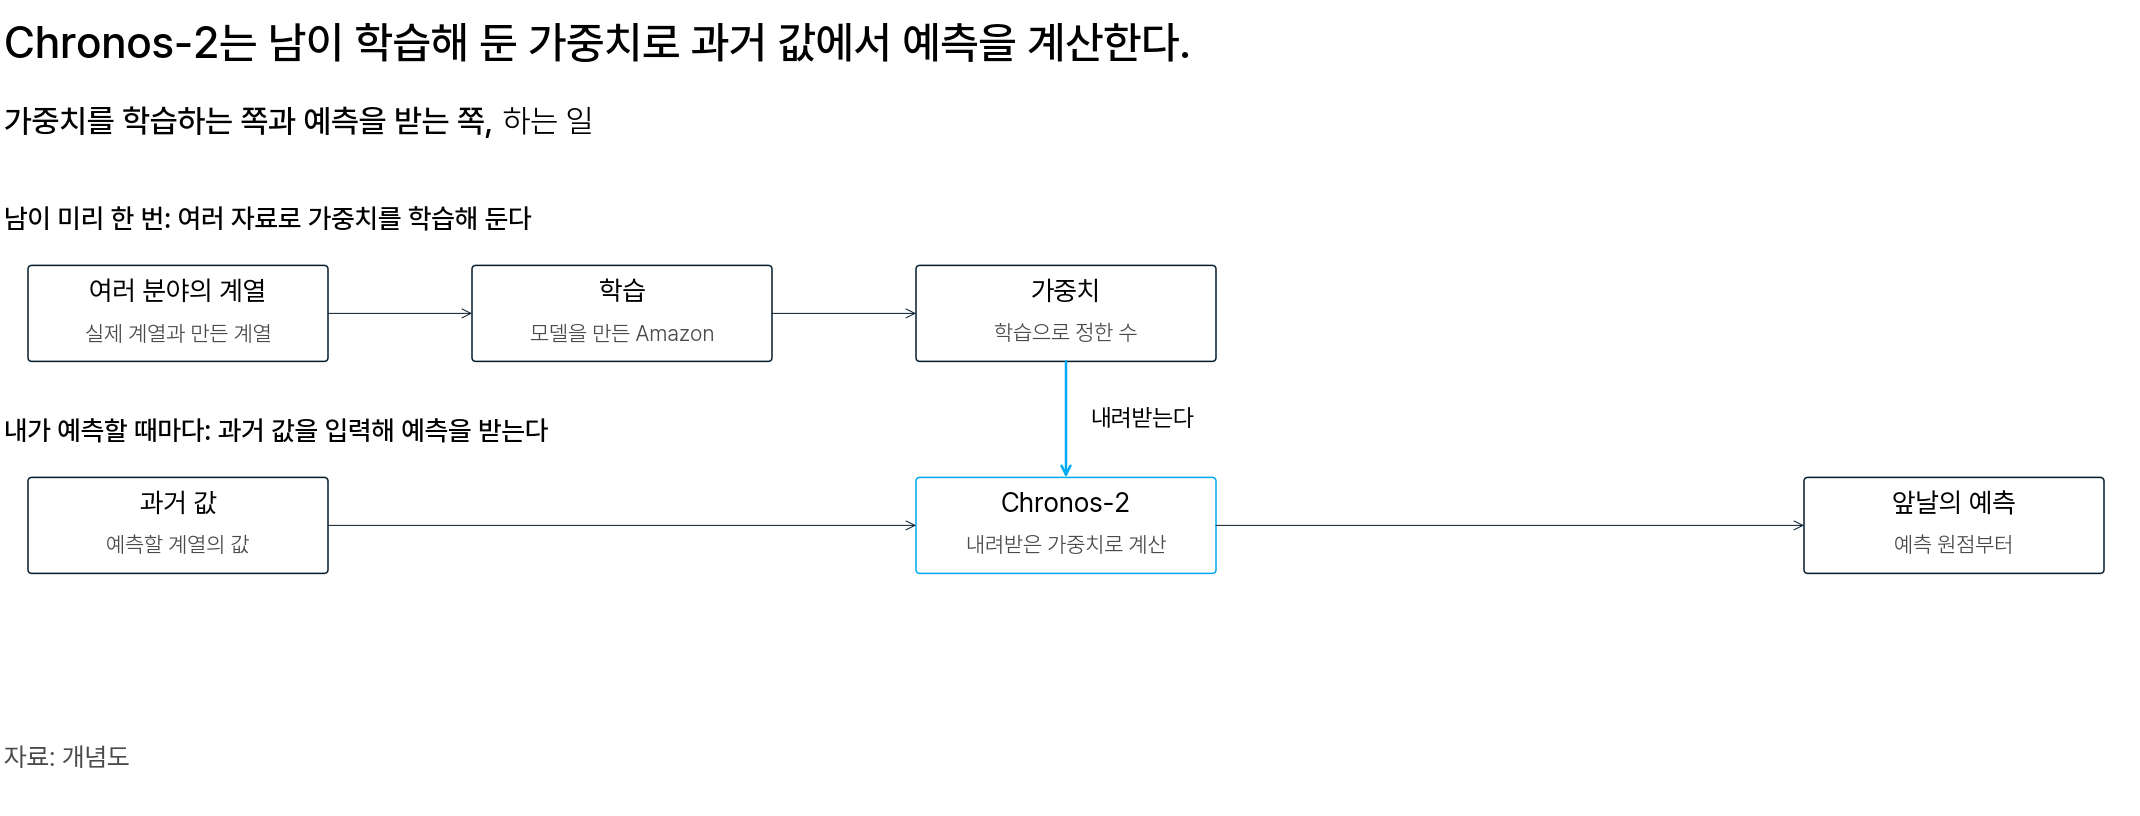

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 위는 모델을 만든 Amazon 이 미리 한 번 한 일이고, 아래는 쓰는 사람이 예측할 때마다 하는 일이다. 위에서 정한 가중치를 내려받아 아래 계산에 쓴다</em></p>

**Chronos-2** 는 Amazon 이 2025년 10월 공개한 시계열 예측 모델입니다.

그림의 「예측 원점」은 예측하는 7일의 첫날입니다.

이 모델을 쓸지 정하려면 세 가지를 알아야 합니다.

- 가중치를 누가, 무엇으로 정했나: 「1. 사전학습·제로샷·미세조정」
- 긴 과거를 어떻게 반영하나: 「2. 트랜스포머와 어텐션」
- 무엇을 입력하고 무엇을 받나: 「3. Chronos-2 의 입력과 출력」

**모델 설명의 예는 가상의 가게 하나이고, 서울 지하철 100개 역의 수는 「4.」부터 나옵니다.**

### 예로 쓸 자료: 가게 하나의 28일 [필수]

모델 설명의 예는 손님 수가 요일마다 되풀이되는 가게 하나입니다.

| 주 | 월 | 화 | 수 | 목 | 금 | 토 | 일 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1주(1～7일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 2주(8～14일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 3주(15～21일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 4주(22～28일째) | 100 | 100 | 100 | 100 | 100 | 60 | 40 |

계산하기 쉽게 정한 값이고, 단위는 명입니다.

28일의 합은 2,400명이라, 하루 평균은 2,400 ÷ 28 ≈ 85.7명입니다.

그래서 100명인 월～금은 평균보다 높은 날이고, 토·일은 낮은 날입니다.

날은 번호로 부릅니다. 1일째가 1주 월요일이고, 28일째가 4주 일요일입니다.

29일째는 다음 월요일입니다.

**평일은 높고 주말은 낮은 모양이 7일마다 되풀이됩니다.**

<div class="lms-summary">

**정리**

Chronos-2 는 남이 학습해 둔 가중치로, 입력한 과거 값에서 앞날의 예측을 계산합니다.

**할 일**

- 「1.」～「3.」에서는 위 가게 표의 수로 직접 계산해 봅니다

이 가게는 평일이 높고 주말이 낮은 모양이 7일마다 되풀이됩니다.

</div>

## 1. 사전학습·제로샷·미세조정

남이 학습해 둔 모델은 내가 학습한 모델과 무엇이 다르고, 쓰는 방법은 몇 가지일까요?

### 사전학습 모델은 첫날 MLP 와 무엇이 다른가 [필수]

가중치를 내가 학습하지 않고, 남이 여러 자료로 미리 정해 둔 것을 가져다 씁니다.

| 구분 | 첫날 글로벌 MLP | 사전학습 모델 Chronos-2 |
|---|---|---|
| 가중치를 정한 자료 | 내 자료(서울 지하철 100개 역) | 여러 분야의 실제 계열과 컴퓨터로 만든 계열 |
| 가중치를 학습한 쪽 | 나 | 모델을 만든 Amazon |
| 내가 하는 일 | 학습한 뒤 예측 | 가중치를 내려받아 예측 |

첫날에는 내 자료로 가중치를 처음부터 학습했습니다.

Chronos-2 는 가중치를 정한 자료도, 학습한 쪽도 다릅니다.

이렇게 수많은 계열로 미리 한 번 학습해 가중치를 정해 두는 것이 **사전학습(pretraining)** 입니다.

**사전학습 모델은 가중치를 학습하는 일을 남이 미리 해 둔 모델입니다.**

<details class="lms-extra"><summary>더 깊이 — 사전학습 자료는 어떻게 모으나</summary>

사전학습 모델은 자연어 처리에서 먼저 널리 쓰였습니다.

<img src="https://d2l.ai/_images/nlp-map-pretrain.svg" alt="자연어 처리에서 맨 아래 사전학습 단계가 정한 결과를 가운데 모델 구조 단계와 맨 위 응용 단계가 가져다 쓰는 구성도" width="980" height="465"/>
<p align="center"><em>▲ 자연어 처리의 세 단계. 맨 아래 Pretraining(사전학습) 단계가 미리 학습한 결과를 가운데 Architecture(모델 구조) 단계가 받아, 맨 위 Application(응용) 단계의 일에 쓴다. 시계열로 옮기면 맨 아래가 Chronos-2 의 사전학습이고, 맨 위가 100개 역의 7일 예측이다 (출처: Zhang 외, Dive into Deep Learning, d2l.ai)</em></p>

맨 아래 상자 넷은 word2vec · BERT 같은 자연어 처리의 사전학습 방법 이름입니다.

가운데 상자는 모델 구조의 이름이고, 맨 위 상자는 감성 분석(Sentiment analysis) 같은 응용 과제의 이름입니다.

위 표의 「여러 분야의 실제 계열과 컴퓨터로 만든 계열」이 사전학습 자료입니다. 실제 계열은 한 분야가 아니라 여러 분야에서 모읍니다. 모델 하나가 주기와 규모가 서로 다른 계열을 모두 예측해야 하기 때문입니다.

<img data-fit="wide" src="https://ar5iv.labs.arxiv.org/html/2402.02592/assets/problem.png" alt="여러 도메인의 시계열을 모델 하나로 예측하는 문제" width="918" height="560"/>
<p align="center"><em>▲ 사전학습 자료를 여러 분야에서 모으는 까닭. 모델 하나가 주기·변수 수·분포 모양이 서로 다른 분야의 계열을 모두 예측해야 한다 (출처: Woo 외, Unified Training of Universal Time Series Forecasting Transformers, arXiv 2402.02592 Figure 1)</em></p>

그림 위의 Multiple Domains 는 여러 분야이고, Universal Forecaster 는 모델 하나입니다.

아래 세 영어 이름은 왼쪽부터 관측 간격(캡션의 주기) · 변수 수 · 분포 모양이 여럿이라는 뜻입니다.

실제 계열만으로는 모양의 가짓수가 모자라, 컴퓨터로 새 계열을 만들어 더합니다. 아래 방법은 1세대 Chronos 논문의 합성 방법입니다. Chronos-2 기술 보고서도 KernelSynth 를 합성 계열의 재료로 썼다고 밝힙니다.

<img data-fit="wide" src="https://arxiv.org/html/2403.07815v3/x3.png" alt="기본 모양 여럿을 골라 조합해 새 시계열을 만드는 절차" width="980" height="526"/>
<p align="center"><em>▲ KernelSynth. 직선으로 오르는 모양, 같은 간격으로 되풀이되는 모양 같은 기본 모양(커널)을 골라 더하거나 곱하고, 그 모양을 따르는 무작위 곡선을 새 계열로 쓴다 (출처: Ansari 외, Chronos: Learning the Language of Time Series, arXiv 2403.07815, 1세대 Chronos)</em></p>

Kernel Bank 의 Linear 는 직선, RBF 는 완만한 오르내림, Periodic 은 되풀이되는 기본 모양입니다.

sample kernels 는 몇 개를 무작위로 고르는 단계이고, 물결표는 그 모양을 따르는 곡선을 뽑았다는 표시입니다.

그래서 사전학습 가중치는 학습한 적 없는 계열에서도 입력의 추세와 요일마다 되풀이되는 모양을 예측에 반영하도록 정해져 있습니다. 그 계열이 어느 규모인지, 주말이 얼마나 낮은지는 입력한 과거 값에서 얻습니다.

</details>

### 학습한 적 없는 계열을 어떻게 예측하나 [필수]

가게의 1～19일째(3주 금요일까지)를 입력합니다.

| 주 | 월 | 화 | 수 | 목 | 금 | 토 | 일 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 1주 | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 2주 | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 3주 | 100 | 100 | 100 | 100 | 100 | ? | |

> **[예측] 20일째(3주 토요일)의 손님 수는 몇 명일까요?**
>
> 1. 40명
> 2. 60명
> 3. 100명
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

60명입니다. 입력에서 같은 모양이 두 번 되풀이되었으니, 그 주기로 이으면 60명입니다.

이 가게는 처음 봤습니다. 그래도 답할 수 있었던 까닭은 둘입니다.

- 되풀이되는 모양은 그 주기로 이어진다는 것: 다른 자료에서 이미 배워 알고 있었습니다
- 이 가게의 7일 주기와 손님 규모: 방금 본 표에서 읽었습니다

모델에서는 이미 배운 것이 사전학습 가중치이고, 방금 본 표가 입력한 과거 값입니다.

Chronos-2 도 학습한 적 없는 가게의 요일 모양과 손님 규모는 입력한 과거 값에서 얻습니다. 그래서 사전학습 모델에도 그 계열의 과거는 꼭 입력합니다.

**학습한 적 없는 계열의 요일 모양과 규모는 가중치가 아니라 입력한 과거 값에서 옵니다.**

### 제로샷은 무엇이 0 인가 [필수]

**제로샷(zero-shot)** 은 이 자료로 가중치를 고치지 않고, 과거 값을 입력으로만 전달해 예측을 받는 것입니다.

$$
\textbf{사전학습 가중치(고정)} + \textbf{과거 값(입력)} \;\longrightarrow\; \textbf{앞날의 예측(출력)}
$$

이름의 0 은 이 자료로 학습한 횟수입니다.

| 흔한 오해 | 실제 |
|---|---|
| 과거 값을 쓰지 않는다 | 학습에는 쓰지 않고 입력으로 쓴다 |
| 예측할 때 조금 학습한다 | 가중치가 그대로라, 같은 과거를 입력하면 같은 예측이 나온다 |
| 휴일도 알아서 반영한다 | 입력에 없는 것은 반영되지 않는다. 가게의 다음 수요일이 휴일이어도 과거 값에 그 표시는 없다 |

**제로샷에서 분석가가 정하는 것은 입력할 과거뿐입니다.**

### 내 자료로 더 학습하면 무엇이 달라지나 [필수]

**미세조정(fine-tuning)** 은 사전학습 가중치에서 출발해 내 자료로 몇 스텝 더 학습하는 것입니다.

**스텝(step)** 은 학습 윈도 여러 개를 읽고 가중치를 한 번 고치는 것입니다. 첫날 학습에서 되풀이한 일입니다.

| 구분 | 제로샷 | 미세조정 | 직접 학습 |
|---|---|---|---|
| 출발하는 가중치 | 사전학습 가중치 | 사전학습 가중치 | 무작위로 정한 처음 값 |
| 내 자료로 가중치를 고치나 | 고치지 않음 | 몇 스텝 고침 | 처음부터 끝까지 고침 |
| 내 자료의 쓰임 | 입력으로만 | 학습과 입력 | 학습과 입력 |
| 이 과정의 예 | Chronos-2 제로샷 | Chronos-2 미세조정 | 첫날 글로벌 MLP |
| 이럴 때 쓴다 | 학습할 시간이 없을 때, 과거 값만 있는 계열을 바로 예측할 때 | 그 자료의 모양을 가중치에 더 담고 싶을 때 | 작은 모델을 그 자료만으로 처음부터 학습할 때 |

세 방식은 내 자료로 가중치를 얼마나 고치느냐로 나뉩니다.

미세조정이 제로샷보다 나은지는 정해져 있지 않습니다. 첫날 평가표와 같은 채점으로 확인합니다.

**제로샷은 가중치를 그대로 두고, 미세조정은 내 자료로 조금 고칩니다.**

<div class="lms-summary">

**정리**

사전학습 모델은 남이 정해 둔 가중치를 가져다 씁니다. 제로샷은 그 가중치를 고치지 않고, 미세조정은 내 자료로 몇 스텝 고칩니다. 학습한 적 없는 계열의 요일 모양과 규모는 입력한 과거 값에서 옵니다.

**할 일**

- 사전학습 모델에도 그 계열의 과거는 꼭 입력합니다

제로샷에서 분석가가 정하는 것은 입력할 과거뿐입니다.

</div>

> **[문제] Chronos-2 제로샷은 예측 원점마다 100개 역의 과거 자료로 가중치를 조금 고친 뒤 예측한다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 2. 트랜스포머와 어텐션

Chronos-2 는 긴 과거 가운데 어느 날을 얼마나 반영해 다음 날을 예측할까요?

### RNN 은 과거를 어떻게 받나 [필수]

RNN 은 과거를 하루씩 차례로 받고, 계산한 결과를 다음 날 계산에 전달합니다.

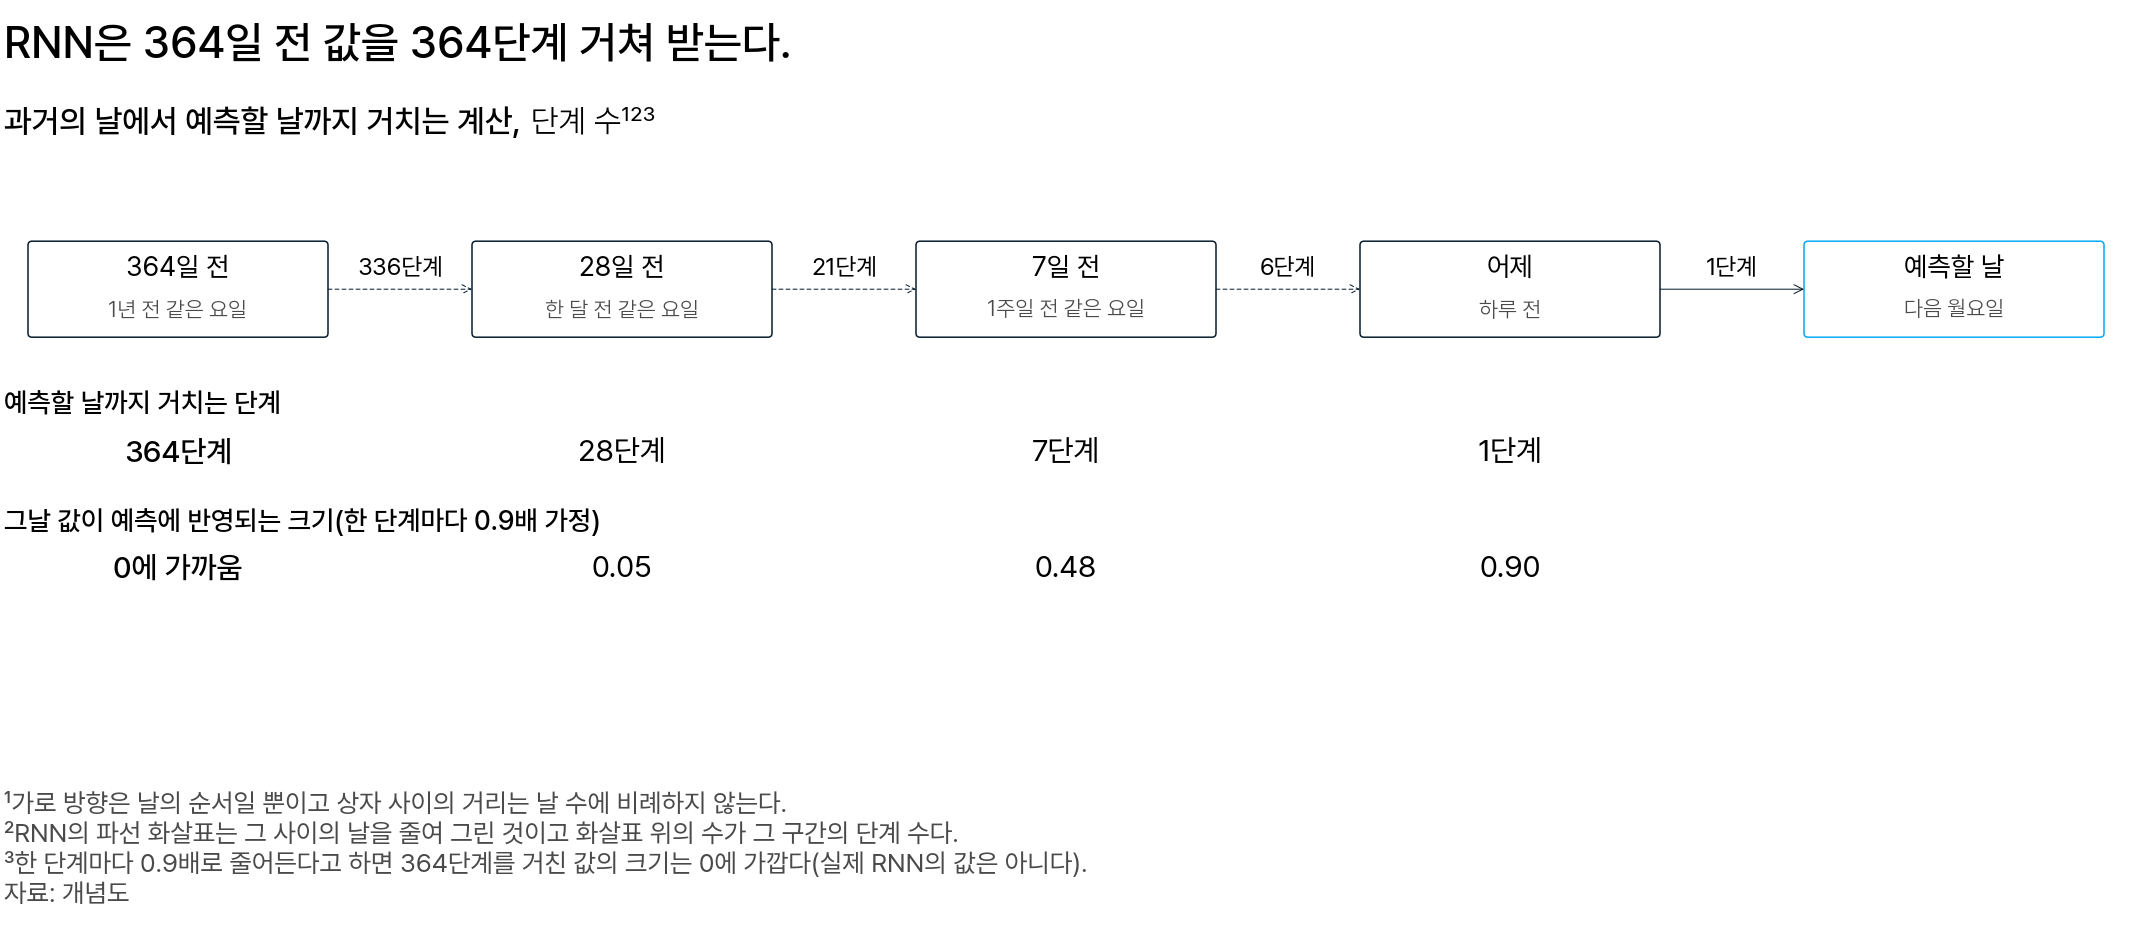

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 상자는 과거의 날과 예측할 날이고, 화살표 위의 수는 두 상자 사이에서 거치는 단계 수다. 아래 두 행은 그날 값이 예측할 날까지 거치는 단계 수와, 한 단계마다 0.9배로 줄어든다고 가정했을 때 예측에 반영되는 크기다</em></p>

**순환 신경망(recurrent neural network, RNN)** 은 과거를 하루씩 차례로 받는 신경망입니다. 1일째를 계산한 결과를 2일째 계산에 전달하고, 마지막 날까지 되풀이합니다.

첫날 MLP 는 28일을 한꺼번에 받았습니다. RNN 은 하루씩 받으므로, 먼 날의 값은 예측에 반영되기까지 여러 단계를 거칩니다.

간단한 예로, 한 단계 전달할 때마다 값이 0.9배로 줄어든다고 해 봅니다. 실제 RNN 의 값은 아닙니다.

그러면 1주일 전 값은 0.9 를 7번 곱한 0.48배만 남습니다.

1년 전 값은 0.9 를 364번 곱해 0 에 가깝습니다.

**단계마다 조금씩 줄어든다면, 364단계를 거친 1년 전 값은 예측에 거의 반영되지 않습니다.**

### 어텐션은 무엇이 다른가 [필수]

어텐션은 예측할 날과 관계 깊은 날의 값을 한 단계에 반영합니다.

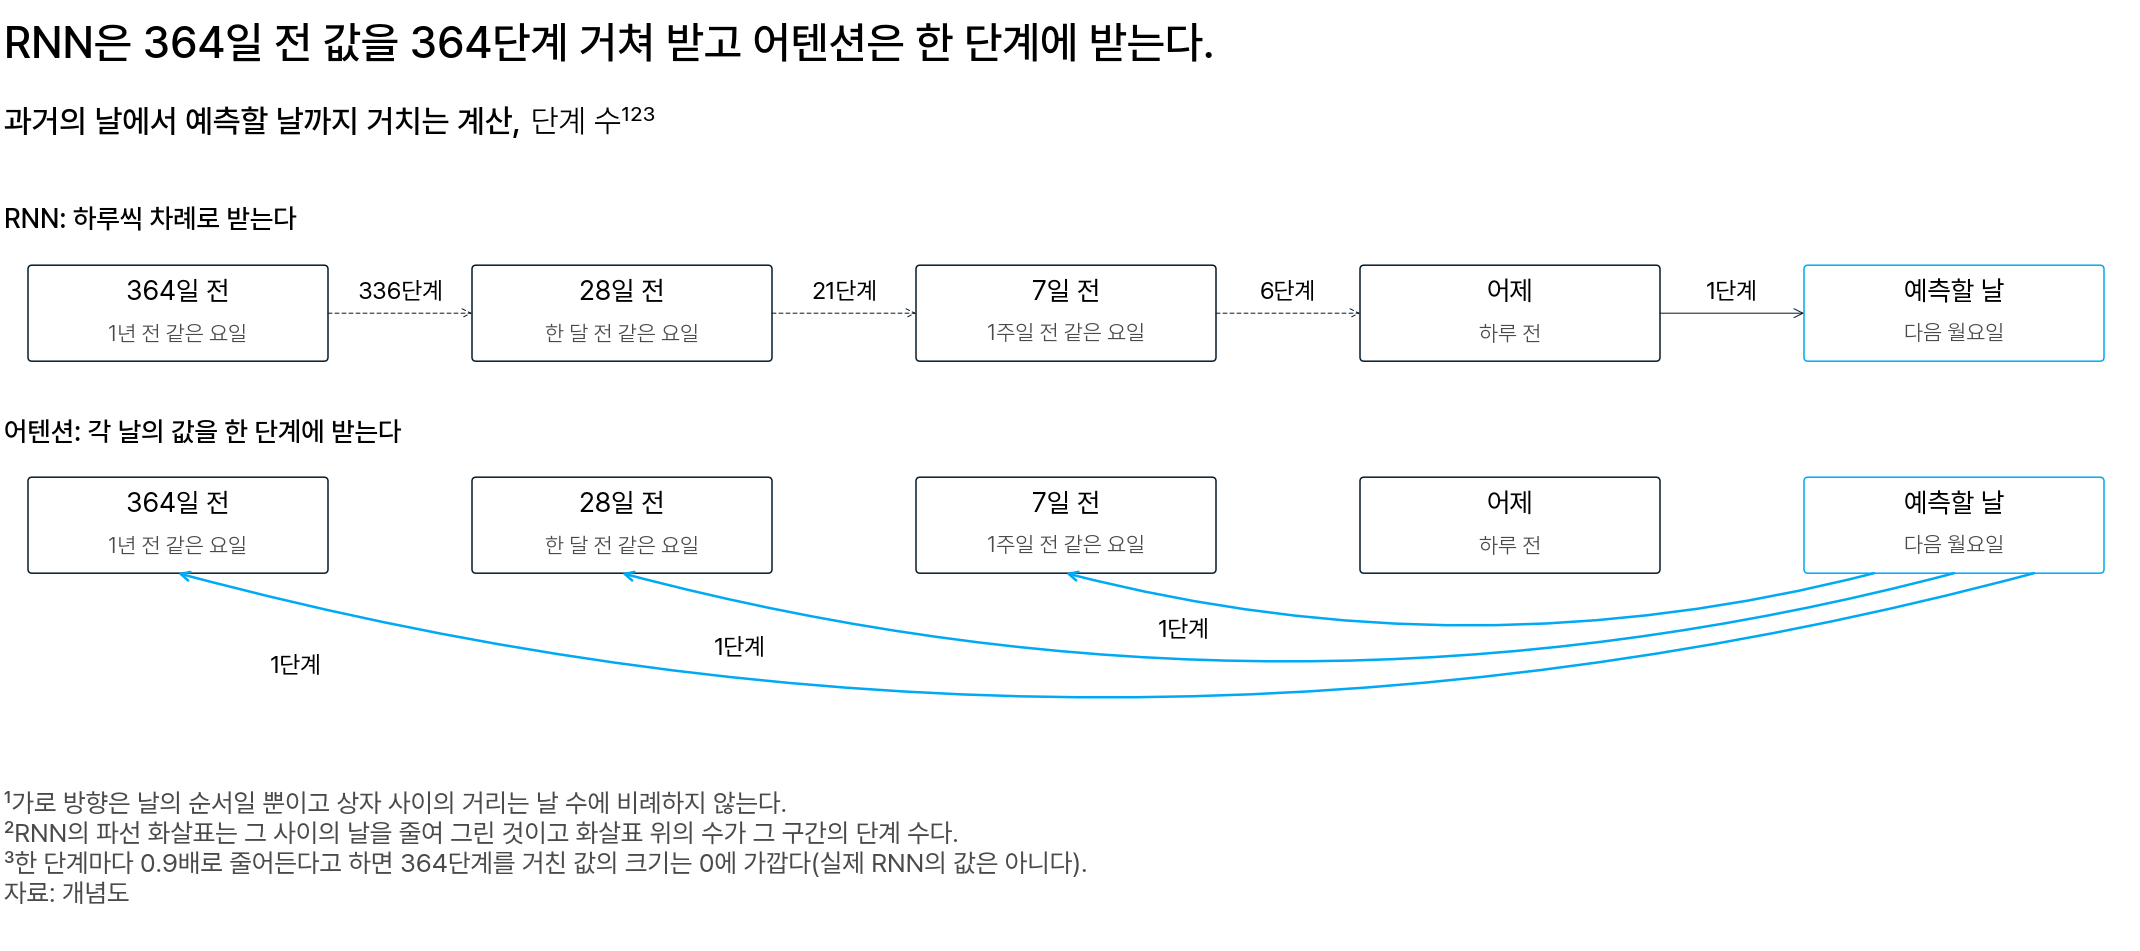

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 위는 RNN 이다. 364일 전 → 28일 전 → 7일 전 → 어제 → 예측할 날을 차례로 잇는다. 아래는 어텐션이다. 화살표가 예측할 날과 7일 전 · 28일 전 · 364일 전을 각각 한 단계로 잇는다</em></p>

**어텐션(attention)** 은 과거의 모든 날을 한꺼번에 받아, 각 날의 값을 한 단계에 반영하는 계산입니다. 7일 전도 364일 전도 한 단계입니다.

사람이 다음 월요일 손님 수를 예측하려고 1주일 전, 한 달 전, 1년 전 같은 요일을 찾아보는 것과 같은 효과입니다.

세 날은 예측할 날과 요일이 같습니다. 가까운 날에서는 요즘 수준을, 1년 전에서는 같은 철의 수준을 알 수 있습니다.

반영할 수 있는 것은 입력에 있는 날뿐입니다. 1년 전 값을 반영하려면 입력이 364일보다 길어야 합니다.

**어텐션은 가까운 날의 값도 먼 날의 값도 한 단계에 반영합니다.**

<details class="lms-extra"><summary>더 깊이 — 떨어진 입력을 잇는 세 방식: CNN·RNN·셀프 어텐션</summary>

CNN(convolutional neural network, 합성곱 신경망)은 이웃한 입력 몇 개씩만 묶어 계산하는 신경망입니다. RNN(recurrent neural network, 순환 신경망)은 입력을 한 시점씩 차례로 받는 신경망입니다.

<img src="https://d2l.ai/_images/cnn-rnn-self-attention.svg" alt="입력 다섯 개를 출력에 잇는 세 방식을 나란히 그린 그림" width="503" height="335"/>
<p align="center"><em>▲ 입력 다섯 개(x₁～x₅)를 출력에 잇는 세 방식. 실선은 떨어진 입력이 한 출력에 닿는 경로다. 왼쪽이 CNN(합성곱 신경망), 오른쪽 위가 RNN(순환 신경망), 오른쪽 아래가 Self-attention 이다 (출처: Zhang 외, Dive into Deep Learning, d2l.ai, 11.6)</em></p>

CNN 에서는 떨어진 x₁ 과 x₅ 가 층을 둘 거쳐야 한 출력에서 만납니다. RNN 은 앞 시점의 계산 결과를 다음 시점에 전달하므로, x₁ 은 화살표 다섯 개를 거쳐야 마지막 출력에 닿습니다.

LSTM(long short-term memory) 같은 RNN 변형은 단계를 거쳐도 값이 덜 줄어들게 만든 것입니다. 그래도 먼 입력이 여러 단계를 거치는 것은 같습니다.

셀프 어텐션(self-attention)은 출력마다 같은 입력의 다섯 위치를 모두 바로 받습니다. 그래서 x₅ 도 화살표 하나로 첫 출력에 닿습니다.

</details>

### 어텐션은 그날의 값을 어떻게 반영하나 [필수]

그날의 값에 큰 가중치를 주어 가중 평균합니다.

**가중 평균**은 값마다 가중치를 곱해 더한 값이고, 가중치의 합은 1 입니다. 가게의 29일째(월요일) 손님 수를 과거 28일의 가중 평균으로 예측해 봅니다.

여기서 가중치는 날마다 주는 비율이고, 「1.」에서 본 모델의 가중치와는 다른 수입니다.

| 방법 | 가중치를 준 날 | 계산 | 예측값 |
|---|---|---|---:|
| 어제 값 그대로 | 28일째(일) 하나에 1 | 40 | 40명 |
| 최근 7일 평균 | 22～28일째에 1/7 씩 | (100 × 5 + 60 + 40) ÷ 7 | 85.7명 |
| 4주의 같은 요일 평균 | 1 · 8 · 15 · 22일째(월)에 1/4 씩 | (100 × 4) ÷ 4 | 100명 |

29일째의 실제 손님 수는 100명입니다.

둘째 방법이 첫날 배운 직전 7일 평균입니다. 계절 나이브는 1주일 전인 22일째 하나에만 가중치 1 을 준 경우입니다.

셋째 방법이 1주일 전부터 4주일 전까지 같은 요일의 값을 한 단계에 반영하는 계산입니다.

**어느 날에 가중치를 주느냐가 예측값을 정합니다.**

### 같은 요일 넷을 고르게 평균하면 무엇이 문제인가 [필수]

평소와 다른 날이 하나 있으면, 고르게 평균한 예측값이 그날 때문에 낮아집니다.

앞 화면의 세 방법은 가중치를 사람이 미리 정했고, 같은 요일 넷에는 1/4 씩 고르게 주었습니다.

이번에는 다음 수요일(31일째)을 예측합니다.

가게의 값을 하루만 바꿉니다. 2주 수요일(10일째)이 휴일이라 손님이 20명이었다고 해 봅니다.

| 가게 | 1주 수요일 | 2주 수요일 | 3주 수요일 | 4주 수요일 | 고르게 평균 |
|---|---:|---:|---:|---:|---:|
| 휴일이 없는 가게 | 100 | 100 | 100 | 100 | 100명 |
| 2주 수요일이 휴일인 가게 | 100 | 20 | 100 | 100 | 80명 |

다음 수요일은 휴일이 아니고, 실제 손님 수는 평소처럼 100명이라고 둡니다.

고르게 평균한 80명은 실제보다 20명 낮습니다.

**평소와 다른 주는 덜 반영해야 하고, 그러려면 가중치를 주마다 다르게 주어야 합니다.**

### 어느 주를 더 반영하나 [필수]

가장 최근 주와 요일 모양이 닮은 주를 더 반영합니다.

앞 화면에서는 같은 요일인 수요일 넷을 쓰기로 사람이 미리 정했습니다. 이제 그 넷 가운데 어느 주의 수요일을 더 크게 반영할지는 입력에서 계산합니다.

예측할 주는 아직 값이 없습니다. 그래서 간단히, 값이 있는 가장 최근 주인 4주를 기준으로 삼아 4주와 닮은 주를 찾습니다.

요일 모양을 비교하므로, 값 대신 평균보다 높은지 낮은지만 봅니다.

휴일 하루로 28일의 합이 80명 줄어, 평균은 85.7명에서 2,320 ÷ 28 ≈ 82.9명으로 낮아집니다.

이 평균보다 높은 날은 +, 낮은 날은 − 부호로 적습니다.

| 요일 | 1주 | 2주(수요일 휴일) | 3주 | 4주(기준) |
|---|:-:|:-:|:-:|:-:|
| 월 | + | + | + | + |
| 화 | + | + | + | + |
| 수 | + | − | + | + |
| 목 | + | + | + | + |
| 금 | + | + | + | + |
| 토 | − | − | − | − |
| 일 | − | − | − | − |

1주와 3주는 모든 요일이 4주와 같고, 2주만 수요일이 다릅니다.

**두 주가 같은 요일에 함께 높거나 함께 낮으면 닮은 주입니다.**

### 닮은 정도를 수로 나타내면 [필수]

두 주의 부호를 요일마다 곱하고, 그 곱 일곱 개를 더한 수가 닮은 정도입니다.

$$
\begin{aligned}
\text{둘 다 높음:}\quad & (+) \times (+) = (+) \\
\text{둘 다 낮음:}\quad & (-) \times (-) = (+) \\
\text{한쪽만 낮음:}\quad & (+) \times (-) = (-)
\end{aligned}
$$

부호가 같은 날의 곱은 +1, 다른 날의 곱은 −1 입니다.

2주와 4주로 계산해 봅니다.

2주의 월요일 부호와 4주의 월요일 부호를 곱합니다. 화요일끼리, 수요일끼리도 같은 방법으로 일요일까지 곱합니다.

| 요일 | 2주 | 4주 | 곱 |
|---|:-:|:-:|---:|
| 월 | + | + | +1 |
| 화 | + | + | +1 |
| 수 | − | + | −1 |
| 목 | + | + | +1 |
| 금 | + | + | +1 |
| 토 | − | − | +1 |
| 일 | − | − | +1 |

곱 일곱 개를 더하면 +1 이 여섯, −1 이 하나라 6 − 1 = 5 입니다.

1주와 3주도 4주의 부호와 요일마다 곱해 더합니다. 4주는 자기 부호끼리 곱해 일곱 날 모두 +1 입니다.

| 주 | 4주와 부호가 같은 날 | 다른 날 | 더한 값 |
|---|---:|---:|---:|
| 1주 | 7 | 0 | 7 |
| 2주 | 6 | 1(수요일) | 6 − 1 = 5 |
| 3주 | 7 | 0 | 7 |
| 4주(기준) | 7 | 0 | 7 |

두 주가 닮은 정도를 수 하나로 나타낸 이 값이 **유사도(similarity)** 입니다.

**수요일이 휴일이던 2주의 유사도가 5 로 가장 작습니다.**

### 유사도를 가중치로 바꾸면 [필수]

유사도를 합이 1 인 비율로 바꾼 값이 어텐션 가중치입니다.

가중 평균에 쓰려면 가중치의 합이 1 이어야 합니다.

유사도를 그대로 비율로 쓰면 5 대 7 이라, 휴일이던 2주의 가중치도 다른 주와 비슷합니다.

2주의 가중치를 더 작게 하려고, 유사도가 1 높을 때마다 비를 2배로 합니다. 2배는 계산하기 쉽게 정한 수입니다.

2주는 다른 주보다 유사도가 2 낮아, 다른 주의 비가 2주의 2 × 2 = 4배입니다.

$$
\begin{aligned}
\text{네 주의 비:}\quad & 4 : 1 : 4 : 4 \quad (\text{합 } 13) \\
\text{가중치:}\quad & 4 \div 13 \approx 0.31, \qquad 1 \div 13 \approx 0.08
\end{aligned}
$$

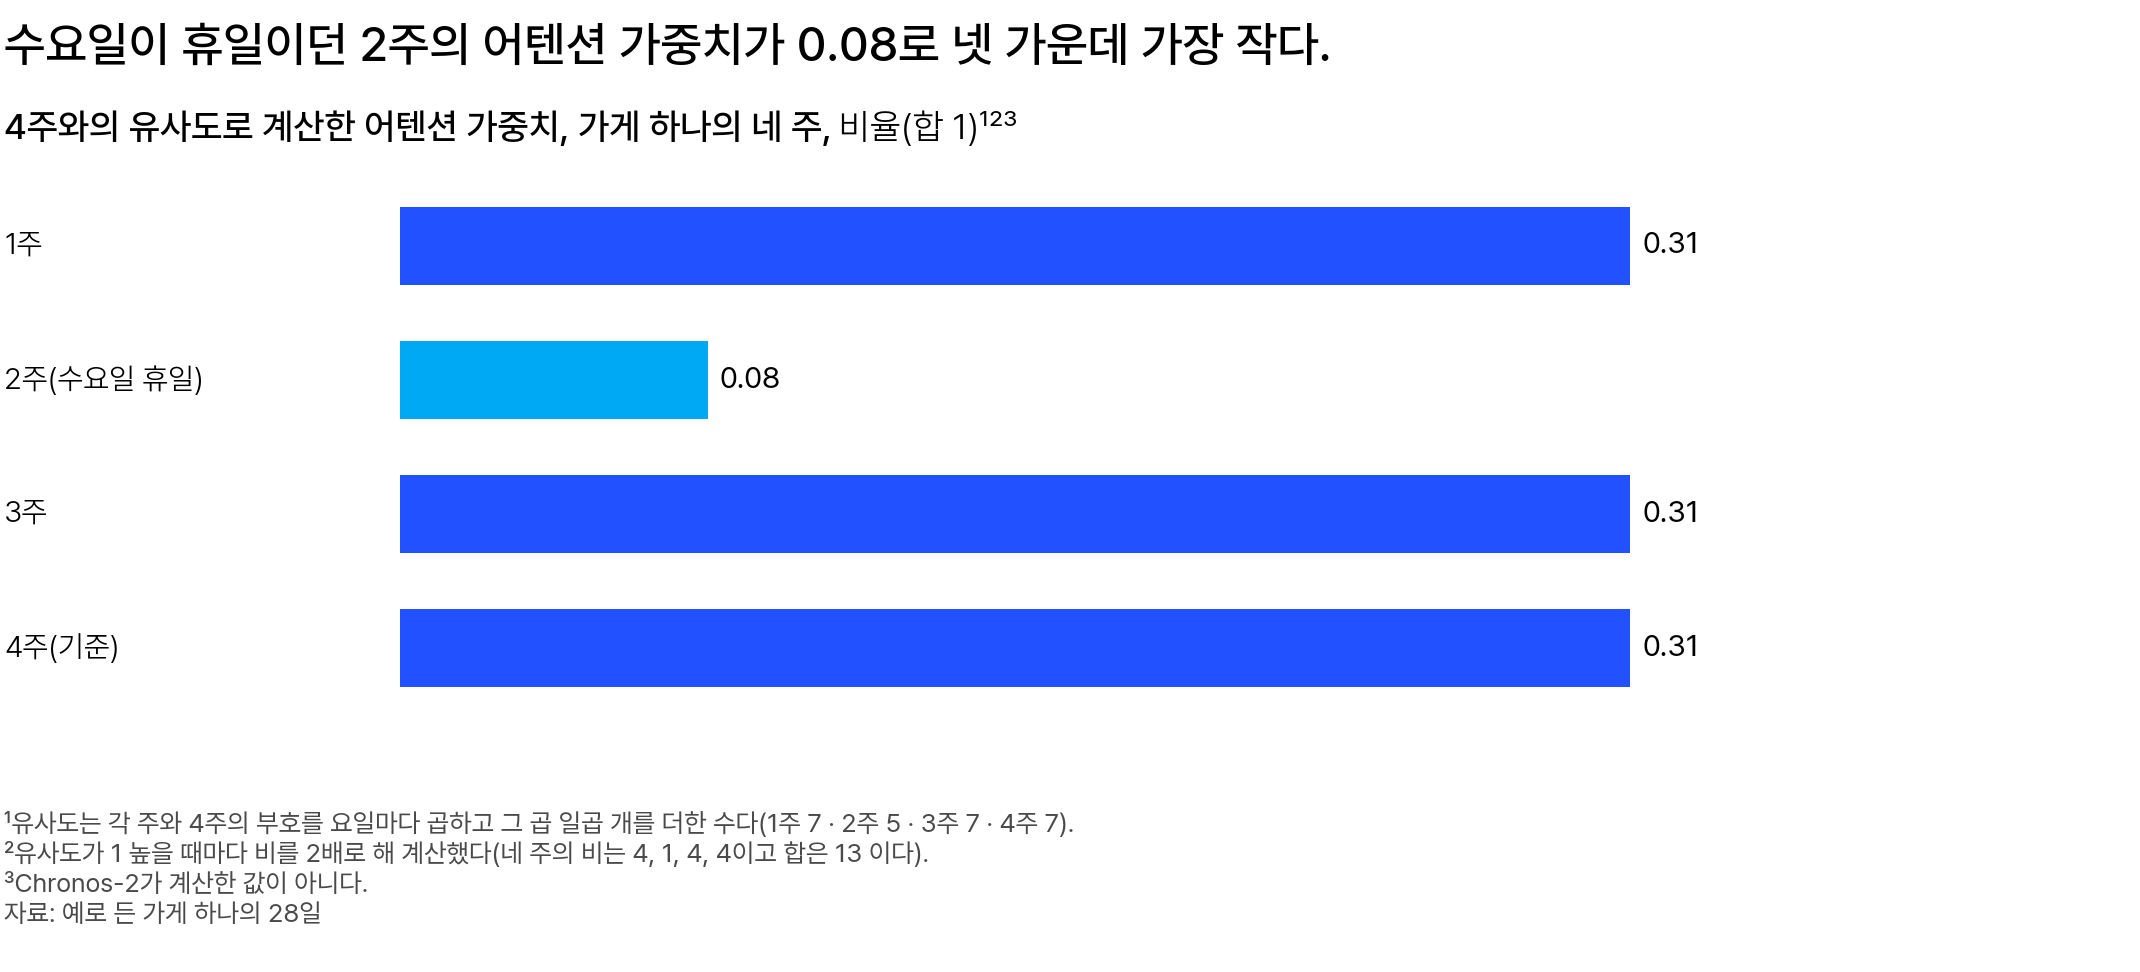

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 막대 하나가 한 주이고, 막대 길이와 끝의 수가 그 주의 어텐션 가중치다(네 주 합 1). 강조한 막대가 수요일이 휴일이던 2주다</em></p>

입력에서 계산한 이 가중치가 **어텐션 가중치(attention weight)** 입니다. 유사도가 1 높을 때마다 같은 배수로 키워 합이 1 인 비율로 바꾸는 이 계산을 **소프트맥스(softmax)** 라고 합니다.

**모양이 다른 2주의 어텐션 가중치가 0.08 로 가장 작습니다.**

<details class="lms-extra"><summary>자세히 — 2배 대신 실제 소프트맥스(약 2.72배)로 계산하면</summary>

실제 소프트맥스는 유사도가 1 높을 때마다 비를 자연상수 e, 곧 약 2.72배로 합니다. 본문의 2배를 이 수로 바꾸는 것 말고는 계산 순서가 같습니다.

2주는 다른 주보다 유사도가 2 낮습니다. 그래서 다른 주의 비는 2주의 e × e, 곧 약 7.39배입니다. 네 주의 비를 합 23.17 로 나누면 가중치입니다.

$$
\begin{aligned}
\text{네 주의 비:}\quad & 7.39 : 1 : 7.39 : 7.39 \quad (\text{합 } 23.17) \\
\text{가중치:}\quad & 7.39 \div 23.17 \approx 0.32, \qquad 1 \div 23.17 \approx 0.04
\end{aligned}
$$

네 주의 가중치는 0.32 · 0.04 · 0.32 · 0.32 입니다. 2주의 가중치는 2배로 계산한 0.08 에서 0.04 로 절반쯤이 됩니다.

네 수요일의 값에 비를 곱해 더하고, 합 23.17 로 나눕니다.

$$
(7.39 \times 100 + 1 \times 20 + 7.39 \times 100 + 7.39 \times 100) \div 23.17 = 2{,}237 \div 23.17 \approx 96.5 \text{ 명}
$$

2배로 계산한 93.8명보다 평소 수요일 100명에 더 가깝습니다. 배수가 클수록 유사도가 낮은 주의 가중치가 더 작아지기 때문입니다.

어느 배수를 써도 순서는 같습니다. 유사도가 가장 낮은 2주의 가중치가 가장 작습니다.

</details>

### 어텐션 가중치로 예측하면 [필수]

> **[예측] 네 수요일을 이 어텐션 가중치로 가중 평균하면, 고르게 평균한 80명보다 클까요?**
>
> 1. 80명보다 작다
> 2. 80명과 같다
> 3. 80명보다 크다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

셋째 보기가 맞습니다.

$$
(4 \times 100 + 1 \times 20 + 4 \times 100 + 4 \times 100) \div 13 = 1{,}220 \div 13 \approx 93.8 \text{ 명}
$$

휴일이던 2주의 20명은 가중치 0.08 로만 반영됩니다.

그래서 고르게 평균한 80명보다 평소 수요일 100명에 가깝습니다.

**모양이 다른 주는 작은 가중치로만 반영됩니다.**

### 입력이 바뀌면 가중치도 바뀌나 [필수]

어텐션 가중치는 미리 정해 둔 수가 아니라, 입력마다 새로 계산합니다.

| 입력 | 네 주의 유사도 | 어텐션 가중치 | 다음 수요일 예측값 |
|---|---|---|---:|
| 2주 수요일이 휴일(20명) | 7 · 5 · 7 · 7 | 0.31 · 0.08 · 0.31 · 0.31 | 93.8명 |
| 2주 수요일이 평소(100명) | 7 · 7 · 7 · 7 | 0.25 · 0.25 · 0.25 · 0.25 | 100명 |

두 행은 같은 날을 같은 규칙으로 계산했고, 달라진 것은 입력뿐입니다.

**입력이 달라지면 어텐션 가중치도 달라집니다.**

아래 셀은 표의 첫 행을 계산합니다. `wed2 = 20` 을 `wed2 = 100` 으로 바꿔 실행하면 둘째 행이 나옵니다.

In [ ]:
# 가게 네 주의 어텐션 가중치 — 유사도가 1 높을 때마다 비를 2배로 해서 계산
import numpy as np

wed2 = 20                                           # 2주 수요일의 손님 수(명). 100 으로 바꿔 다시 실행해 봅니다
shop = np.array([[100, 100, 100, 100, 100, 60, 40]] * 4)   # 네 주 × 월～일의 손님 수
shop[1, 2] = wed2
sign = np.where(shop > shop.mean(), 1, -1)          # 평균보다 높은 날 +1, 낮은 날 -1
sim = sign @ sign[3]                                # 각 주와 4주의 부호를 요일마다 곱해 더한 유사도
w = 2.0 ** sim / (2.0 ** sim).sum()                 # 합이 1 인 비율 = 어텐션 가중치
print("유사도", sim, "→ 가중치", w.round(2), "→ 다음 수요일 예측값", round(float(w @ shop[:, 2]), 1))

### 모델 가중치와 어텐션 가중치는 무엇이 다른가 [필수]

Chronos-2 에는 가중치가 두 가지 있습니다.

| 구분 | 모델 가중치 | 어텐션 가중치 |
|---|---|---|
| 언제 정하나 | 사전학습 때 한 번 | 예측할 때마다 입력에서 계산 |
| 제로샷에서 입력이 바뀌면 | 그대로 | 달라진다 |

사전학습 때 정한 가중치가 **모델 가중치**입니다. 첫날 MLP 의 가중치도 모델 가중치입니다.

어텐션 가중치를 계산하는 방법은 모델 가중치 안에 있습니다.

**모델 가중치는 고정이고, 어텐션 가중치는 입력마다 달라집니다.**

### 트랜스포머는 무엇인가 [필수]

트랜스포머는 어텐션 계산을 여러 층 되풀이하는 신경망입니다.

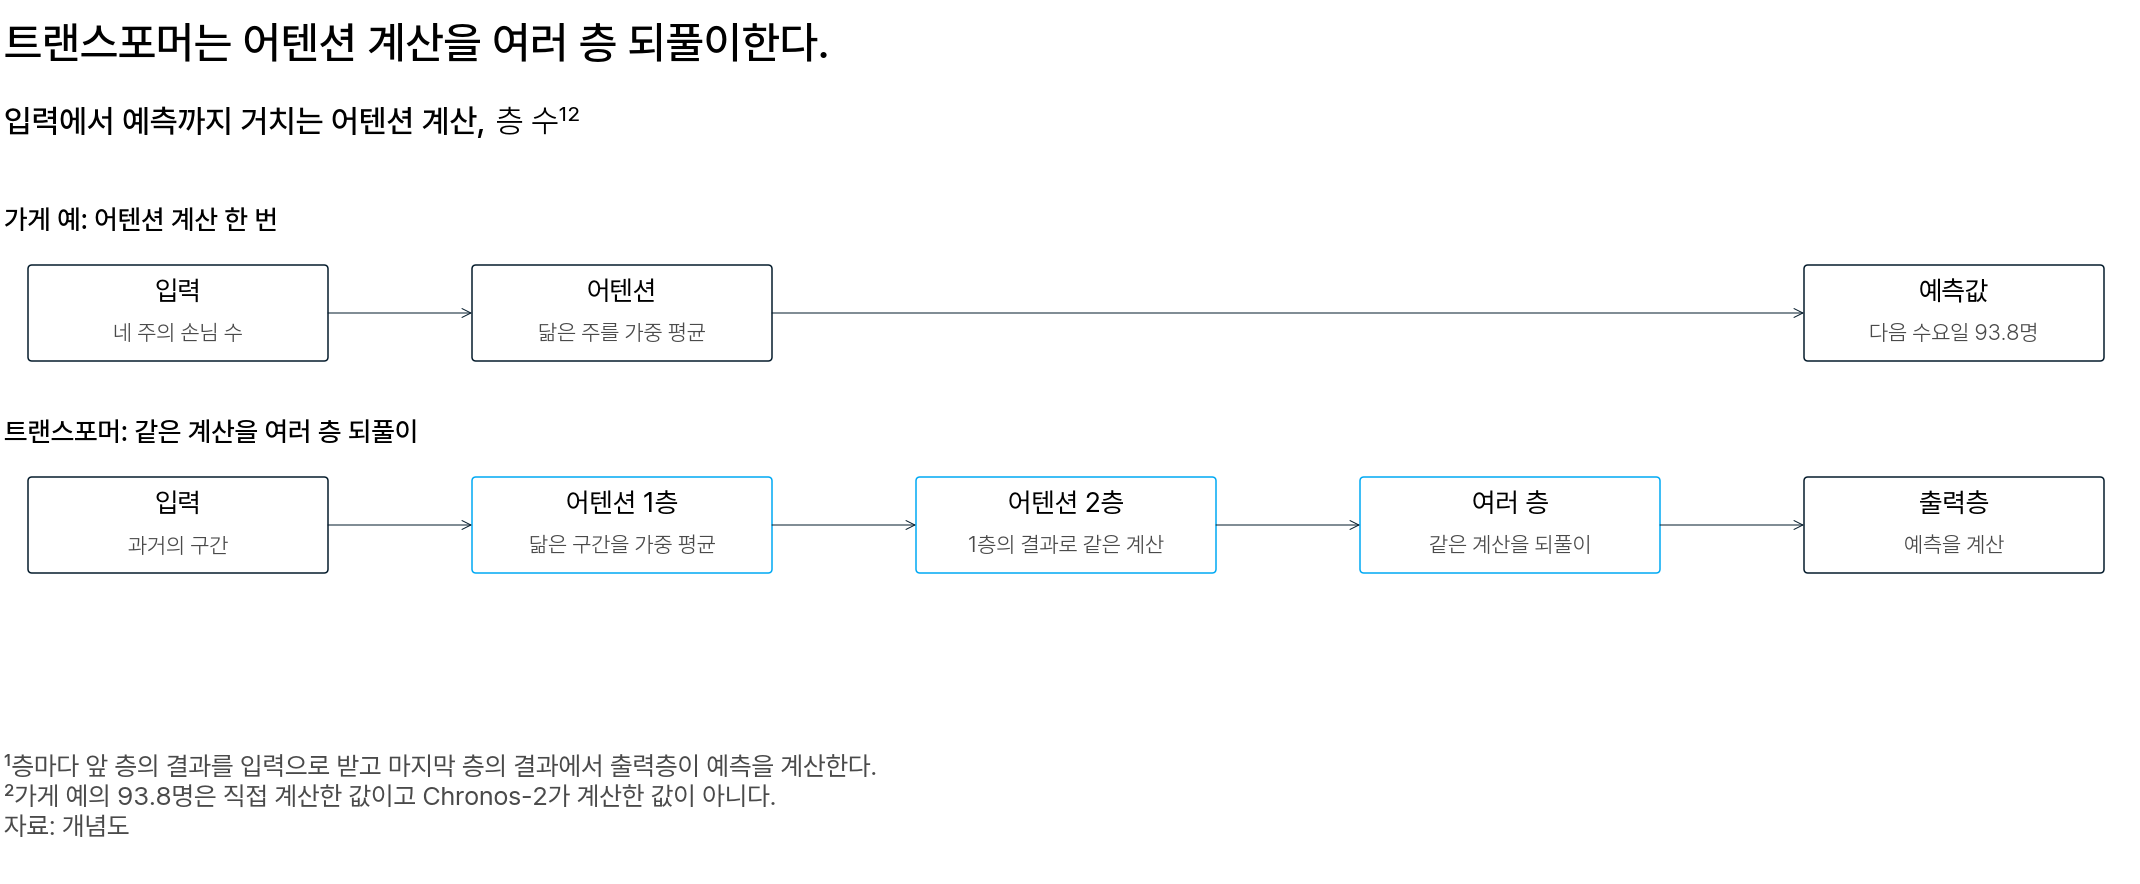

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 위는 가게 예다. 어텐션 계산 한 번으로 예측값을 계산했다. 아래는 트랜스포머다. 같은 계산을 여러 층 되풀이하고, 마지막에 출력층이 예측을 계산한다</em></p>

가게 예에서 네 주를 가중 평균한 계산 한 번이 한 층입니다.

가게 예는 다음 수요일 하나만 계산했습니다. 실제 한 층은 구간마다 계산해, 구간 수만큼 새 값을 얻습니다.

다음 층은 그 새 값들을 입력으로 받아 같은 계산을 다시 합니다.

그래서 가중 평균한 값끼리 닮은 정도를 다시 계산합니다.

마지막 층의 결과로 예측을 계산하는 부분이 출력층입니다.

이렇게 어텐션을 여러 층 되풀이하는 신경망이 **트랜스포머(transformer)** 이고, Chronos-2 는 트랜스포머입니다.

**트랜스포머는 「닮은 구간에 큰 가중치」 계산을 여러 층 되풀이합니다.**

### Chronos-2 의 어텐션은 이 예와 무엇이 다른가 [필수]

계산의 구조는 같고, 비교하는 단위 · 닮은 정도를 나타내는 수 · 계산 횟수가 다릅니다.

| 구분 | 가게 예 | Chronos-2 |
|---|---|---|
| 비교하는 단위 | 한 주(7일) | 16일 구간(「3. Chronos-2 의 입력과 출력」에서 패치라 부른다) |
| 닮은 정도를 나타내는 수 | 높음 · 낮음 부호 | 모델 가중치로 계산한 수. 어떤 구간끼리 닮았다고 할지도 사전학습으로 정한다 |
| 계산 횟수 | 한 번(한 층) | 같은 계산을 여러 층 되풀이 |

**Chronos-2 는 「닮은 구간에 큰 가중치」 계산을 16일 단위로 여러 층 되풀이합니다.**

<details class="lms-extra"><summary>더 깊이 — 실제 모델의 어텐션 가중치를 읽을 때</summary>

층이 여럿이라, 한 층에서 작게 반영된 구간도 다른 층에서 다시 반영될 수 있습니다. 그래서 가게 예의 2주처럼 한 층의 가중치가 작아도, 그 구간이 예측에 쓰이지 않았다고 말할 수 없습니다.

위 가게 예는 높음 · 낮음 부호를 그대로 곱했습니다. 두 주의 부호를 요일마다 곱하고 그 곱을 모두 더하는 이 계산의 이름이 내적(dot product)입니다.

실제 트랜스포머는 입력 값에 모델 가중치의 행렬을 곱해 새 값을 만들고, 새 값끼리 곱해 더합니다. 모델 가중치는 고정이지만 곱하는 입력이 달라, 어텐션 가중치는 입력마다 새로 나옵니다.

가중 평균이 곧 예측값인 것도 아닙니다. 한 층의 가중 평균은 다음 층의 입력이고, 마지막에 출력층이 예측을 계산합니다.

실제 Chronos-2 는 예측할 구간도 값이 빈 채로 함께 입력하고, 예측은 그 구간에서 계산합니다. 가게 예에서 가장 최근 주를 기준으로 삼은 것은 계산을 간단히 하려던 것이고, 실제 모델의 계산과는 다릅니다.

어텐션 가중치가 작으면 그 구간이 지금 구간과 덜 닮았다고 짐작할 수 있을 뿐입니다. 모델이 그 구간의 값을 쓰지 않았다는 뜻은 아닙니다.

Chronos-2 안에는 어텐션 계산이 여러 층에 걸쳐 있고, 한 층의 가중치는 다음 계산으로 넘어가는 여러 값 가운데 하나를 정할 뿐입니다. 자연어 모델 연구에서도 어텐션 가중치를 바꿔도 출력이 거의 달라지지 않는 예가 보고되었습니다(Jain · Wallace, 「Attention is not Explanation」, 2019).

그래서 어텐션 가중치는 「이 주에 작은 가중치를 매기는 경향이 보인다」 정도로 적습니다. 어느 날이 예측에 얼마나 쓰였는지 확인하려면, 그날 입력값을 바꾼 뒤 예측이 얼마나 달라지는지 봅니다.

</details>

<div class="lms-summary">

**정리**

어텐션은 예측할 날과 관계 깊은 날의 값을 한 단계에 반영하는 계산입니다. 방법은 닮은 구간에 큰 가중치를 주는 가중 평균이고, 가중치는 입력마다 새로 계산합니다. 트랜스포머는 이 계산을 여러 층 되풀이합니다.

**할 일**

- 1년 전 같은 요일의 값까지 반영하려면 과거를 364일보다 길게 입력합니다

RNN 은 하루씩 전달하고, 어텐션은 1주일 전 · 한 달 전 · 1년 전 같은 요일 값도 한 단계에 반영할 수 있습니다.

</div>

## 3. Chronos-2 의 입력과 출력

Chronos-2 에 무엇을 입력하고 무엇을 받을까요?

### 모델은 과거를 어떤 단위로 받나 [필수]

모델은 과거를 하루씩 받지 않고, 며칠을 묶어 한 단위로 받습니다.

| 구분 | 가게 예 | Chronos-2 |
|---|---|---|
| 입력 길이 | 28일 | 512일 |
| 한 단위의 길이 | 7일 | 16일 |
| 단위의 수 | 28 ÷ 7 = 4개 | 512 ÷ 16 = 32개 |

하루 값 하나로는 그 주가 어떤 모양인지 알 수 없습니다. 7일을 묶으면 평일은 높고 주말은 낮은 한 주의 모양이 보입니다.

모델이 한 단위로 받는 것이 **토큰(token)** 입니다. 언어 모델에서는 낱말이나 그보다 작은 단위가 토큰입니다.

며칠을 묶은 토큰이 **패치(patch)** 입니다. 가게 예의 네 주가 7일 패치 4개였습니다.

Chronos-2 의 16일 패치 하나에는 평일과 주말이 두 번쯤 들어 있어, 패치 하나에서도 요일 모양이 보입니다.

패치끼리는 가게 예처럼 부호를 곱해 더하지 않고, 모델 가중치로 계산한 수로 닮은 정도를 나타냅니다. 닮은 구간에 큰 가중치를 주는 계산은 가게 예와 같습니다.

**Chronos-2 는 512일을 16일 패치 32개로 받습니다.**

<details class="lms-extra"><summary>자세히 — 묶으면 비교할 짝이 얼마나 줄어드나</summary>

어텐션은 토큰마다 모든 토큰과 닮은 정도를 계산합니다. 그래서 비교할 짝의 수는 토큰 수 × 토큰 수입니다.

| 입력 | 하루가 토큰일 때 | 패치가 토큰일 때 | 줄어드는 배수 |
|---|---:|---:|---:|
| 가게 예 28일(7일 패치) | 28 × 28 = 784 | 4 × 4 = 16 | 49배 |
| Chronos-2 512일(16일 패치) | 512 × 512 = 262,144 | 32 × 32 = 1,024 | 256배 |

하루를 토큰 하나로 두면 512일 입력에서 비교할 짝이 26만 개를 넘습니다.

16일씩 묶으면 짝이 1,024개로 줄어듭니다.

줄어드는 배수는 묶는 날 수의 제곱입니다. 7일 패치는 7 × 7 = 49배, 16일 패치는 16 × 16 = 256배입니다.

짝이 줄면 같은 계산량으로 더 긴 과거를 입력할 수 있습니다.

대신 패치 안의 하루하루를 따로 비교하지는 않습니다. 패치 하나가 한 단위이기 때문입니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 패치를 널리 알린 PatchTST 의 구조 그림을 기호부터 읽으면</summary>

아래는 패치로 자르는 방법을 널리 알린 모델 PatchTST 의 구조 그림이고, Chronos-2 의 그림이 아닙니다.

<img data-fit="wide" src="https://ar5iv.labs.arxiv.org/html/2211.14730/assets/fig_model.png" alt="위쪽에 계열 여럿을 하나씩 같은 트랜스포머에 입력해 예측 표를 만드는 전체 구조, 아래쪽에 한 계열을 패치로 잘라 트랜스포머 인코더에 입력하는 두 구조를 그린 PatchTST 구조 그림" width="712" height="559"/>
<p align="center"><em>▲ PatchTST 의 구조. 위쪽 (a) 는 전체 구조, 아래 왼쪽 (b) 는 예측할 때의 구조, 아래 오른쪽 (c) 는 가린 패치를 되살리는 사전학습 구조다 (출처: Nie 외, A Time Series is Worth 64 Words, ICLR 2023, arXiv 2211.14730 Figure 1)</em></p>

(a) 왼쪽 끝에 적힌 $x \in \mathbb{R}^{M \times L}$ 은 「실수를 행 $M$개 · 열 $L$개로 적은 표 $x$」로 읽습니다.

| 기호 | 뜻 | 가게 예 | 이 과정 |
|---|---|---|---|
| $\mathbb{R}$ | 실수 전체 | 손님 수 100 | 역의 하루 값 |
| $M$ | 계열 수 | 가게 2곳 | 100개 역 |
| $L$ | 입력 길이 | 28일 | 512일 |
| $T$ | 예측 길이 | 7일 | 7일 |
| $x \in \mathbb{R}^{M \times L}$ | 입력 표. 계열 $M$개의 과거 $L$일 | 2 × 28 표 | 100 × 512 표 |
| $x^{(i)} \in \mathbb{R}^{1 \times L}$ | $i$번째 계열 하나. 입력 표의 한 행 | 가게 A 의 28일 | 역 하나의 512일 |
| $\hat{x} \in \mathbb{R}^{M \times T}$ | 예측 표. ^ 표시는 예측값이라는 뜻 | 2 × 7 표 | 100 × 7 표 |
| $\hat{x}^{(i)} \in \mathbb{R}^{1 \times T}$ | $i$번째 계열의 예측. 예측 표의 한 행 | 가게 A 의 7일 | 역 하나의 7일 |

그림은 계열을 5개 그렸지만, 실제 $M$ 은 자료마다 다릅니다.

초록 선 한 줄이 계열 하나의 과거 입력이고, 파란 선 한 줄이 그 계열의 예측입니다.

그림 아래의 $i = 1, \dots, M$ 은 첫 계열부터 $M$번째 계열까지 하나씩이라는 뜻입니다.

| (a) 의 영어 이름(왼쪽부터) | 하는 일 |
|---|---|
| Channel-independence | 입력 표를 계열 하나씩 나눈다. 채널(channel)은 계열 하나를 뜻한다 |
| Transformer Backbone | 계열 하나를 받아 예측 한 행 $\hat{x}^{(i)}$ 를 계산한다 |
| Concatenate | 계열마다 나온 예측 행을 다시 한 표로 합친다 |

가게 두 곳의 다음 7일 예측이 아래와 같다고 해 봅니다.

| 계열 | 월 | 화 | 수 | 목 | 금 | 토 | 일 |
|---|---:|---:|---:|---:|---:|---:|---:|
| 가게 A | 100 | 100 | 100 | 100 | 100 | 60 | 40 |
| 가게 B | 30 | 30 | 30 | 30 | 30 | 20 | 10 |

이 두 행을 한 표로 합친 것이 2 × 7 예측 표 $\hat{x}$ 입니다.

계열을 하나씩 따로 입력해도 모델을 계열 수만큼 학습하는 것은 아닙니다.

Transformer Backbone 은 하나이고, 모든 계열이 그 가중치를 함께 씁니다.

모델 하나를 100개 역이 함께 쓴 첫날의 글로벌 MLP 와 같은 방식입니다.

(b) 는 Transformer Backbone 의 안이고, 상자를 아래에서 위로 읽습니다.

맨 아래 Input Univariate Series 는 계열 하나의 입력입니다.

맨 위 Output Univariate Series 는 그 계열의 예측입니다.

Instance Norm + Patching 은 계열을 표준화해 패치로 자릅니다. 이 상자 위에 그린 막대 하나가 패치 하나입니다.

Projection 은 패치 하나의 수 $P$개를 가중치로 계산해 수 $D$개로 바꿉니다.

Position Embedding 은 그 패치가 몇 번째 패치인지 나타내는 수를 더합니다.

Transformer Encoder 는 어텐션 층입니다.

Flatten 은 패치마다 나온 수를 한 줄로 잇습니다.

Linear Head 는 그 수로 예측을 계산하는 출력층입니다.

(b) 왼쪽에 세로로 적힌 기호는 상자를 지날 때마다 나온 결과이고, 아래부터 읽습니다.

| (b) 왼쪽 기호(아래부터) | 뜻 | 어느 상자를 지난 뒤 | 가게 예 |
|---|---|---|---|
| $x^{(i)} \in \mathbb{R}^{1 \times L}$ | 계열 하나의 입력 | 상자를 지나기 전 | 가게 A 의 28일 |
| $x_p^{(i)} \in \mathbb{R}^{P \times N}$ | 패치로 자른 계열. 길이 $P$ 인 패치 $N$개. 아래첨자 $p$ 는 패치(patch) | Instance Norm + Patching | 겹치지 않게 7일씩 자르면 $P = 7$, $N = 4$ |
| $x_d^{(i)} \in \mathbb{R}^{D \times N}$ | 패치마다 수 $D$개로 바꾼 것. $D$ 는 패치 하나를 나타내는 수의 개수 | Projection + Position Embedding | 패치 4개마다 수 $D$개 |
| $z^{(i)} \in \mathbb{R}^{D \times N}$ | 어텐션 층을 지난 결과. 크기는 $x_d^{(i)}$ 와 같다 | Transformer Encoder | 패치 4개마다 수 $D$개 |
| $\hat{x}^{(i)} \in \mathbb{R}^{1 \times T}$ | 이 계열의 예측 한 행 | Flatten + Linear Head | 가게 A 의 7일 |

$D$ 는 자료에서 나오는 값이 아니라 모델을 만들 때 정하는 값입니다.

PatchTST 는 패치를 겹치게 자를 수도 있고, 그때는 $N$ 이 더 큽니다.

Transformer Encoder 에서 주황 점선으로 이어진 회색 상자는 어텐션 층 하나의 안입니다.

| 회색 상자의 이름(아래부터) | 하는 일 |
|---|---|
| Multi-Head Attention | 패치끼리 어텐션을 계산한다. 어텐션을 여러 개 나란히 계산해 합친다 |
| Add & Norm | 계산 전의 값을 더하고(점선 화살표) 값의 크기를 고르게 맞춘다 |
| Feed Forward | 어텐션 결과를 패치마다 따로 한 번 더 계산하는 작은 신경망 |
| n× | 이 층 하나를 n번 되풀이한다 |

(c) 는 점선 상자의 패치를 가리고 그 값을 되살리도록 학습하는 사전학습입니다.

맨 위의 회색 막대 셋(Reconstructed Masked Patches)이 되살린 패치입니다.

(b) 의 Flatten + Linear Head 대신 들어간 Linear Layer 가 그 값을 계산하는 출력층입니다.

나머지 상자는 (b) 와 같습니다.

Chronos-2 와 비교하면 아래와 같습니다.

| 구분 | PatchTST | Chronos-2 |
|---|---|---|
| 한 계열의 예측에 다른 계열의 값 | 쓰지 않는다 | 값 한 열만 입력하면 기본 설정에서 쓰지 않는다 |
| 출력 | 예측할 날마다 값 하나 | 예측할 날마다 분위수 여럿 |

공휴일 표시 같은 다른 열을 함께 입력하는 경우는 셋째 날에 다룹니다.

</details>

### 과거를 얼마나 길게 입력하나 [필수]

입력하는 과거의 길이가 컨텍스트 길이이고, 이 과정은 512일을 입력합니다.

| 반영하려는 날 | 며칠 전 | 입력 28일 | 입력 512일 |
|---|---:|---|---|
| 1주일 전 같은 요일 | 7 | 있음 | 있음 |
| 한 달 전(4주) 같은 요일 | 28 | 있음(가장 앞 날) | 있음 |
| 1년 전(52주) 같은 요일 | 364 | 없음 | 있음 |

예측 원점은 예측하는 7일의 첫날입니다. 원점 전날부터 거슬러 입력하는 날 수가 **컨텍스트 길이(context length)** 입니다.

512일은 이 과정이 정한 값입니다. 1년 전 같은 요일이 들어가고, 16일 패치 32개로 나누어떨어집니다.

컨텍스트의 마지막 날은 원점 전날입니다. 가게 예에서 원점이 29일째이면 마지막 날은 28일째입니다.

어텐션은 어느 날에 큰 가중치를 줄지 정하고, 컨텍스트 길이는 며칠 전 값까지 반영할 수 있는지 정합니다.

512일 입력에 1년 전 값이 있어도, 실제로 그날에 큰 가중치를 주는지는 확인하지 않았습니다.

**512일을 입력하면 1년 전 같은 요일 값까지, 28일이면 한 달 전 값까지만 반영할 수 있습니다.**

### 입력 표는 어떤 모양인가 [필수]

열이 셋인 표를 전달합니다. 한 행에는 계열 하나의 하루 값을 적습니다.

| `item_id` | `timestamp` | `target` |
|---|---|---:|
| 가게 A | 1일째(월) | 100 |
| 가게 A | 2일째(화) | 100 |
| … | … | … |
| 가게 A | 28일째(일) | 40 |
| 가게 B | 1일째(월) | 30 |

이 모양이 **롱 포맷(long format)** 이고, 예측을 받는 함수 `predict_df` 에 전달합니다.

세 열은 계열 이름 `item_id`, 날짜 `timestamp`, 값 `target` 입니다. 실제 표의 `timestamp` 에는 날짜를 적습니다.

가게 B 는 표 하나에 계열을 여럿 적을 수 있음을 보이려고 둔 둘째 가게입니다.

다른 열을 남기면 오류 없이 그 열도 입력으로 쓰입니다. 그래서 값 한 열로 예측하려면 세 열만 남깁니다.

**입력 표에는 `item_id` · `timestamp` · `target` 세 열만 남깁니다.**

<details class="lms-extra"><summary>더 깊이 — Chronos-2 를 부를 때 정하는 값</summary>

실습에서는 `BaseChronosPipeline.from_pretrained("amazon/chronos-2")` 로 가중치를 내려받고, `predict_df` 에 아래 값을 정해 부릅니다.

| 인자 | 이 과정의 값 | 뜻 |
|---|---|---|
| 첫 인자(과거 표) | `item_id` · `timestamp` · `target` 세 열 | 원점 전날까지의 과거 값 |
| `prediction_length` | 7 | 원점부터 한 번에 받을 날 수 |
| `quantile_levels` | 0.1, 0.2, …, 0.9 | 받을 값 아홉 개의 확률. 뜻은 바로 다음 「출력은 왜 값 하나가 아닌가」에서 설명한다 |
| `context_length` | 512 | 원점 전날부터 거슬러 전달할 날 수 |
| `freq` | `"D"` | 하루 간격 자료라는 표시 |

`timestamp` 열은 계열마다 행을 날짜 순서로 정렬하고, 예측으로 받는 7일의 날짜를 정하는 데 쓰입니다.

모델이 입력으로 받는 값은 `target` 과 남겨 둔 다른 열뿐입니다. 그래서 모델은 날짜 열에서 요일이나 공휴일 같은 달력 정보를 받지 않습니다.

`target` 옆에 다른 열을 남기면 `predict_df` 는 그 열도 입력으로 씁니다. 이렇게 함께 입력하는 열을 보조 입력, 곧 공변량(covariate)이라 합니다.

가중치를 고치는 인자는 없습니다. 제로샷에서 분석가가 정하는 것은 전달할 표와 이 네 값뿐입니다.

</details>

### 출력은 왜 값 하나가 아닌가 [필수]

값 하나로는 얼마나 빗나갈 수 있는지 알 수 없어, 확률이 서로 다른 값 여러 개를 받습니다.

첫날 MLP 는 날마다 값 하나를 냈습니다. 지금까지는 가게의 수요일도 늘 100명으로 두었습니다.

실제 가게는 같은 수요일도 날마다 조금씩 다릅니다. 그래서 같은 가게의 지난 수요일 10번이 아래와 같았다고 해 봅니다. 작은 값부터 적었습니다.

| 손님 수(명) | 80 | 85 | 90 | 95 | 100 | 105 | 110 | 115 | 120 | 150 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 그 값 이하인 날(10번 가운데) | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| 분위수 | 0.1 | 0.2 | 0.3 | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 | 1.0 |

80명 이하인 날은 10번 가운데 1번이라, 80명이 0.1 분위수입니다.

이렇게 실제가 그 값 이하일 확률로 정한 값이 **분위수(quantile)** 입니다.

같은 방법으로 120명은 0.9 분위수입니다. 80명보다 많고 120명 이하인 날은 8번입니다.

**0.1 분위수와 0.9 분위수 사이에는 10번 가운데 8번이 있습니다.**

### 출력 표는 어떤 모양인가 [필수]

예측할 날마다 분위수 여러 개를 한 행으로 받습니다.

| `item_id` | `timestamp` | `"0.1"` | `"0.5"` | `"0.9"` | `predictions` |
|---|---|---:|---:|---:|---:|
| 가게 A | 다음 수요일 | 80 | 100 | 120 | 100 |
| … | … | … | … | … | … |

앞의 수요일 10번 표는 지난 값으로 분위수의 뜻을 보인 것입니다.

모델의 0.1 분위수는 다음 수요일 손님 수가 그 값 이하일 확률을 모델이 10% 로 계산한 값입니다.

모델이 계산한 분위수가 지난 수요일 10번의 분위수와 같다면, 출력 표의 한 행은 위와 같습니다.

이 과정은 `"0.1"`～`"0.9"` 아홉 열을 받고, 표에는 세 열만 옮겼습니다. `predictions` 열은 `"0.5"` 열과 같은 값입니다.

7일을 예측하면 계열마다 7행입니다.

**출력 표의 한 행은 계열 하나의 하루 예측이고, 열은 분위수입니다.**

### 평가표에는 어느 값을 적나 [필수]

절대 오차로 채점하면 0.5 분위수가 가장 덜 빗나갑니다.

평가표는 방식마다 MASE 를 적는 첫날의 표이고, 날마다 예측값 하나가 필요합니다. 그 값이 **점 예측(point forecast)** 입니다.

지난 수요일 10번을 값 하나로 예측했다고 하고 세 분위수를 비교합니다.

| 예측값으로 쓴 분위수 | 값 | 10번의 평균 절대 오차 |
|---|---:|---:|
| 0.1 | 80명 | 25명 |
| 0.5 | 100명 | 15명 |
| 0.9 | 120명 | 21명 |

$$
(20 + 15 + 10 + 5 + 0 + 5 + 10 + 15 + 20 + 50) \div 10 = 15
$$

식은 100명으로 예측한 행의 계산이고, 더한 수는 날마다 실제와 100명의 차입니다. 세 값 가운데 100명일 때 15명으로 가장 작습니다.

MASE 는 절대 오차를 평균해 채점하는 지표입니다. 그래서 가운데 값(중앙값)인 0.5 분위수가 가장 덜 빗나갑니다.

`predictions` 열은 이름만으로는 어느 분위수인지 알 수 없어, `"0.5"` 열을 직접 꺼냅니다.

**MASE 로 채점하는 평가표에는 `"0.5"` 열을 점 예측으로 씁니다.**

### 7일을 어떻게 받나 [필수]

예측 원점에서 7일을 한 번에 받습니다.

원점 전날까지의 입력으로 7일을 한 번에 받는 방법이 「7일을 한 번에 예측」(multi-step forecast)입니다. 첫날 MLP 도 이렇게 냈습니다(첫날의 다중 출력 방식).

날마다 전날 실제값을 받아 다음 날만 다시 예측할 수도 있습니다. 이 방법이 「날마다 다시 예측」(rolling forecast)입니다.

원점이 수요일일 때 두 방법은 입력의 끝이 아래처럼 다릅니다.

| 예측할 날 | 한 번에 받을 때 입력의 끝 | 날마다 다시 예측할 때 입력의 끝 |
|---|---|---|
| 수요일(원점) | 화요일 | 화요일 |
| 토요일 | 화요일 | 금요일(원점 뒤 실제값 3일 포함) |
| 다음 화요일 | 화요일 | 월요일(원점 뒤 실제값 6일 포함) |

수요일 아침에 그 주 7일의 계획을 한꺼번에 정한다면, 그 아침에는 원점 뒤 실제값이 없어 다시 예측할 수 없습니다.

**평가표에는 원점에서 한 번에 받은 7일만 적습니다.**

### Chronos-2 의 계산 차례를 한 장으로 보면 [선택]

과거 값을 패치로 나누고, 어텐션 층을 여러 번 지난 뒤, 분위수를 계산합니다.

<img src="https://arxiv.org/html/2510.15821v1/x1.png" alt="입력 계열이 패치로 잘려 트랜스포머 층을 지나고 분위수 출력층에서 예측으로 나오는 Chronos-2 흐름도" width="640" height="264"/>
<p align="center"><em>▲ Chronos-2 의 흐름. INPUT 을 TOKENIZATION 에서 패치로 자르고, 어텐션 층으로 이루어진 TRANSFORMER STACK 을 N번 차례로(그림의 x N) 지난 뒤 분위수 출력층 QUANTILE HEAD 가 분위수 예측을 낸다. 아래쪽은 위 단계의 안을 자세히 그린 것이다 (출처: Ansari 외, arXiv 2510.15821 Figure 1)</em></p>

| 그림의 단계 | 이 과정에서 하는 일 |
|---|---|
| INPUT | 과거 512일을 받는다 |
| TOKENIZATION | 16일 패치 32개로 나눈다 |
| TRANSFORMER STACK | 어텐션 계산을 여러 층 되풀이한다 |
| QUANTILE HEAD | 예측할 날마다 분위수를 계산한다 |

**Chronos-2 는 입력, 패치, 어텐션 층, 분위수 출력의 차례로 계산합니다.**

<details class="lms-extra"><summary>자세히 — 그림에 적힌 영어 이름을 차례로 읽으면</summary>

위 표의 네 단계 말고 그림에 적힌 나머지 이름은 왼쪽부터 아래와 같습니다.

| 그림의 이름 | 하는 일 |
|---|---|
| TARGET(S) | 예측할 계열. 이 과정에서는 `target` 열 하나다 |
| KNOWN COVARIATE | 예측할 날의 값도 미리 아는 다른 열(미래 공변량). 값 한 열만 입력하면 없다 |
| HISTORY · FUTURE | 원점 앞의 과거와 예측할 기간. FUTURE 에서 예측할 계열은 값이 비어 있다 |
| ROBUST SCALING | 계열마다 과거 값의 평균과 표준편차로 표준화하고, 로그와 비슷한 변환을 한 번 더 한다 |
| META FEATURES | 값마다 Time Index 와 Mask 를 추가한다 |
| Time Index | 날짜가 아니라 순서를 나타내는 번호 |
| Mask | 값이 있는 날과 비어 있는 날을 구분하는 표시 |
| PATCHING · PATCH EMBEDDING | 16일씩 자르고, 패치마다 값 · Time Index · Mask 를 가중치로 계산해 수 여러 개로 바꾼다. 이 결과가 토큰이고, 그림에서 화살표 셋이 모이는 동그라미다 |
| TIME ATTENTION | 한 계열 안에서 패치끼리 어텐션을 계산한다(attention along time axis) |
| GROUP ATTENTION | 같은 그룹의 계열끼리 같은 위치의 패치로 어텐션을 계산한다(attention within groups) |
| FEED FORWARD | 어텐션 결과를 패치마다 따로 한 번 더 계산하는 작은 신경망 |
| x N | 위 세 계산을 N번 되풀이한다. Chronos-2 는 12번이다 |
| UNSCALING | 표준화한 값을 원래 단위로 복원한다 |
| FORECAST | 원래 단위의 분위수 예측. 예측할 계열에만 있다 |

아래쪽 TIME ATTENTION · GROUP ATTENTION 그림에서는 동그라미 하나가 토큰 하나입니다.

가로 한 줄이 계열 하나이고, 왼쪽에서 오른쪽이 패치의 순서입니다.

TIME ATTENTION 의 가로 회색 상자는 한 계열 안의 토큰끼리 계산한다는 표시입니다.

GROUP ATTENTION 의 세로 회색 상자는 같은 위치에서 그룹 안의 계열끼리 계산한다는 표시입니다.

그룹(group)은 어텐션에서 서로의 값을 반영할 수 있는 계열들을 말합니다.

그림의 #1 과 #2 가 그룹의 번호이고, 색이 같은 계열이 같은 그룹입니다.

값 한 열만 입력하면 기본 설정에서는 계열 하나가 그룹 하나입니다.

그래서 GROUP ATTENTION 에서 다른 계열의 값을 쓰지 않습니다.

</details>

### 모델이 받지 않는 것은 무엇인가 [필수]

Chronos-2 제로샷이 한 계열의 예측에 쓰는 정보는 전달한 과거 값이 전부입니다.

| 정보 | 입력에 있나 |
|---|---|
| 그 계열의 과거 값 | 있음 |
| 날짜와 요일 | 없음 |
| 예측할 날이 휴일인지 | 없음 |
| 다른 계열의 값 | 없음 |

`timestamp` 열은 행을 날짜 순서로 정렬하고 예측 행의 날짜를 정하는 데만 쓰입니다.

예측의 요일 모양은 날짜에서 오지 않고, 과거 값이 7일마다 되풀이되는 데서 옵니다.

그래서 가게의 다음 수요일이 휴일이어도 입력은 같고, 입력이 같으면 예측도 같습니다.

여러 계열을 한 표로 전달해도 기본 설정에서는 계열마다 따로 예측합니다. 가게 A 의 예측에 가게 B 의 값은 쓰이지 않습니다.

**모델은 날짜를 받지 않아, 예측할 날이 휴일인지는 입력에 없습니다.**

<div class="lms-summary">

**정리**

Chronos-2 에는 세 열의 롱 포맷 표로 원점 전날까지의 과거를 전달하고, 예측할 날마다 분위수 아홉 개를 받습니다. 점 예측은 `"0.5"` 열입니다.

**할 일**

- 입력 표에는 `item_id`·`timestamp`·`target` 세 열만 남깁니다
- 평가표에는 원점에서 한 번에 받은 7일의 `"0.5"` 열을 적습니다

모델이 쓰는 정보는 전달한 과거 값이 전부이고, 날짜는 입력에 없습니다.

</div>

> **[문제] 평가표에 적을 Chronos-2 의 점 예측 열**
>
> Chronos-2 는 분위수 아홉 열을 돌려줍니다. 역 단위 MASE 로 채점하는 평가표에는 어느 열을 점 예측으로 적을까요?
>
> 1. `"0.9"` 열: 높게 잡아야 인력이 모자라지 않는다
> 2. `"0.5"` 열: 중앙값이라 절대 오차로 채점하는 MASE 와 맞는다
> 3. `"0.1"` 열: 적게 잡아야 인력이 남지 않는다

## 4. 서울 지하철 100개 역에 Chronos-2 를 쓰면

학습 없이 쓰는 Chronos-2 를 다음 주 역별 인력 예측에 넣을까요?

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Seoul_subway_linemap_ko.svg" alt="서울 지하철 노선도" width="480" height="546"/>
<p align="center"><em>▲ 서울 지하철 노선도. 예측할 역은 첫날과 같은 100개 역이고, 노선 13개에 걸쳐 있다 (출처: Wikimedia Commons, Seoul subway linemap ko.svg)</em></p>

자료는 첫날과 같은 서울 지하철 100개 역 표입니다.

**여기부터 나오는 수는 모두 이 100개 역에서 예측 원점 5개를 채점한 값입니다.**

### 무엇과 비교해 판단하나 [필수]

첫날 평가표의 네 방식과 같은 채점 규칙으로 비교합니다.

| 용어 | 뜻 |
|---|---|
| 예측 원점 | 예측하는 7일의 첫날. 원점 5개는 모두 수요일이고, 원점 전날까지의 자료로 예측한다 |
| 계절 나이브 | 1주일 전 같은 요일 값을 예측값으로 쓰는 베이스라인 |
| 역 단위 MASE | 역마다 채점 7일의 평균 절대 오차를 MASE 분모로 나누고, 100개 역에서 평균한 값 |
| MASE 분모 | 원점 전날까지 계절 나이브가 그 역에서 빗나간 크기의 평균 |

MASE 가 1 이면 평소 빗나가던 만큼 빗나간 것입니다.

**새 모델도 같은 원점 5개에서 같은 역 단위 MASE 로 채점합니다.**

### 왜 다섯 주를 공휴일이 있는 주와 없는 주로 나누나 [필수]

다섯 주 가운데 세 주에 평일 공휴일이 있어, 한꺼번에 평균하면 공휴일 없는 주의 오차가 보이지 않습니다.

| 예측 원점 | 그 주의 평일 공휴일 | 채점한 주 |
|---|---|---|
| 2025-08-13 | 광복절 | 공휴일 있는 세 주 |
| 2025-10-01 | 개천절과 추석 연휴 | 공휴일 있는 세 주 |
| 2025-12-10 | 없음 | 공휴일 없는 두 주 |
| 2026-02-11 | 설 연휴 | 공휴일 있는 세 주 |
| 2026-06-24 | 없음 | 공휴일 없는 두 주 |

「3. Chronos-2 의 입력과 출력」에서 본 대로 Chronos-2 도 날짜를 받지 않습니다.

**그래서 원점 5개를 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 평균합니다.**

### 첫날 평가표의 네 방식은 MASE 가 얼마였나 [필수]

네 방식 모두 공휴일 있는 세 주의 MASE 가 공휴일 없는 두 주보다 큽니다.

| 방식 | 어떤 방식인가 | 평균 MASE | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---|---:|---:|---:|
| 계절 나이브 | 1주일 전 같은 요일 값 | 1.838 | 0.445 | 2.767 |
| 직전 7일 평균 | 역 운영팀이 지금 쓰는 방식 | 2.984 | 1.935 | 3.684 |
| 글로벌 MLP(MSE 손실) | 첫날 100개 역으로 학습한 신경망 | 1.848 | 0.739 | 2.587 |
| 글로벌 MLP(MAE 손실) | 같은 신경망, 손실만 MAE | 1.774 | 0.359 | 2.717 |

평균 MASE 는 원점 5개의 평균입니다.

**새 모델을 쓰려면 먼저 공휴일 없는 두 주에서 계절 나이브 0.445 보다 MASE 가 낮아야 합니다.**

### MASE 차가 얼마나 커야 모델 차이로 읽나 [필수]

다시 학습만 해도 생기는 차보다 커야 모델의 차이로 읽습니다.

시드는 가중치의 처음 값과 학습 순서를 정하는 난수의 출발값입니다. 시드만 바꿔 다시 학습해도 MASE 가 달라집니다.

| 값 | 수 | 어디서 온 수인가 |
|---|---:|---|
| 가장 큰 평균 MASE | 1.848 | 첫날 MLP(MSE 손실)를 시드 0～4 로 다시 학습한 원점 5개 평균 다섯 값 가운데 |
| 가장 작은 평균 MASE | 1.771 | 같은 다섯 값 가운데 |
| 시드 범위 | 0.077 | 1.848 − 1.771 |

가장 큰 값에서 가장 작은 값을 뺀 0.077 을 **시드 범위**라 부릅니다.

모델은 그대로 두고 다시 학습만 해도 평균 MASE 가 이만큼 달라집니다.

학습이 없는 제로샷과 계절 나이브의 차도, 공휴일 없는 두 주나 있는 세 주만 평균한 MASE 의 차도 시드 범위를 참고 기준으로 비교합니다.

**평균 MASE 차는 시드 범위 0.077 과 비교하고, 그보다 작으면 차이로 읽지 않습니다.**

### Chronos-2 에 무엇을 전달하고 무엇을 받았나 [필수]

원점마다 100개 역의 512일을 세 열로 전달하고, 역마다 7일의 분위수를 받았습니다.

원점 2026-06-24 에 전달한 입력 표와 받은 출력 표의 강남역 행입니다(단위: 명).

| 표 | `item_id` | `timestamp` | 값 |
|---|---|---|---|
| 입력 | 0(2호선 강남) | 2025-01-28(설 연휴) | `target` 20,086 |
| 입력 | 0(2호선 강남) | 2026-06-23 | `target` 94,098 |
| 출력 | 0(2호선 강남) | 2026-06-24 | `"0.1"` 90,183 · `"0.5"` 94,030 · `"0.9"` 96,069 |

입력 표는 역마다 원점 전날까지 512일을 적어 100 × 512 = 51,200행입니다.

출력 표는 역마다 7행이라 100 × 7 = 700행입니다. 분위수 아홉 열 가운데 세 열만 옮겼습니다.

06-24 의 실제 승차 94,303명은 0.1 분위수와 0.9 분위수 사이였습니다.

**평가표에는 점 예측인 `"0.5"` 열을 실제 승차와 비교한 값을 적습니다.**

### 강남역 입력 512일에는 무엇이 있나 [필수]

입력 512일에는 매주 되풀이되는 토·일의 낮은 승차와 지난 설·추석이 있습니다.

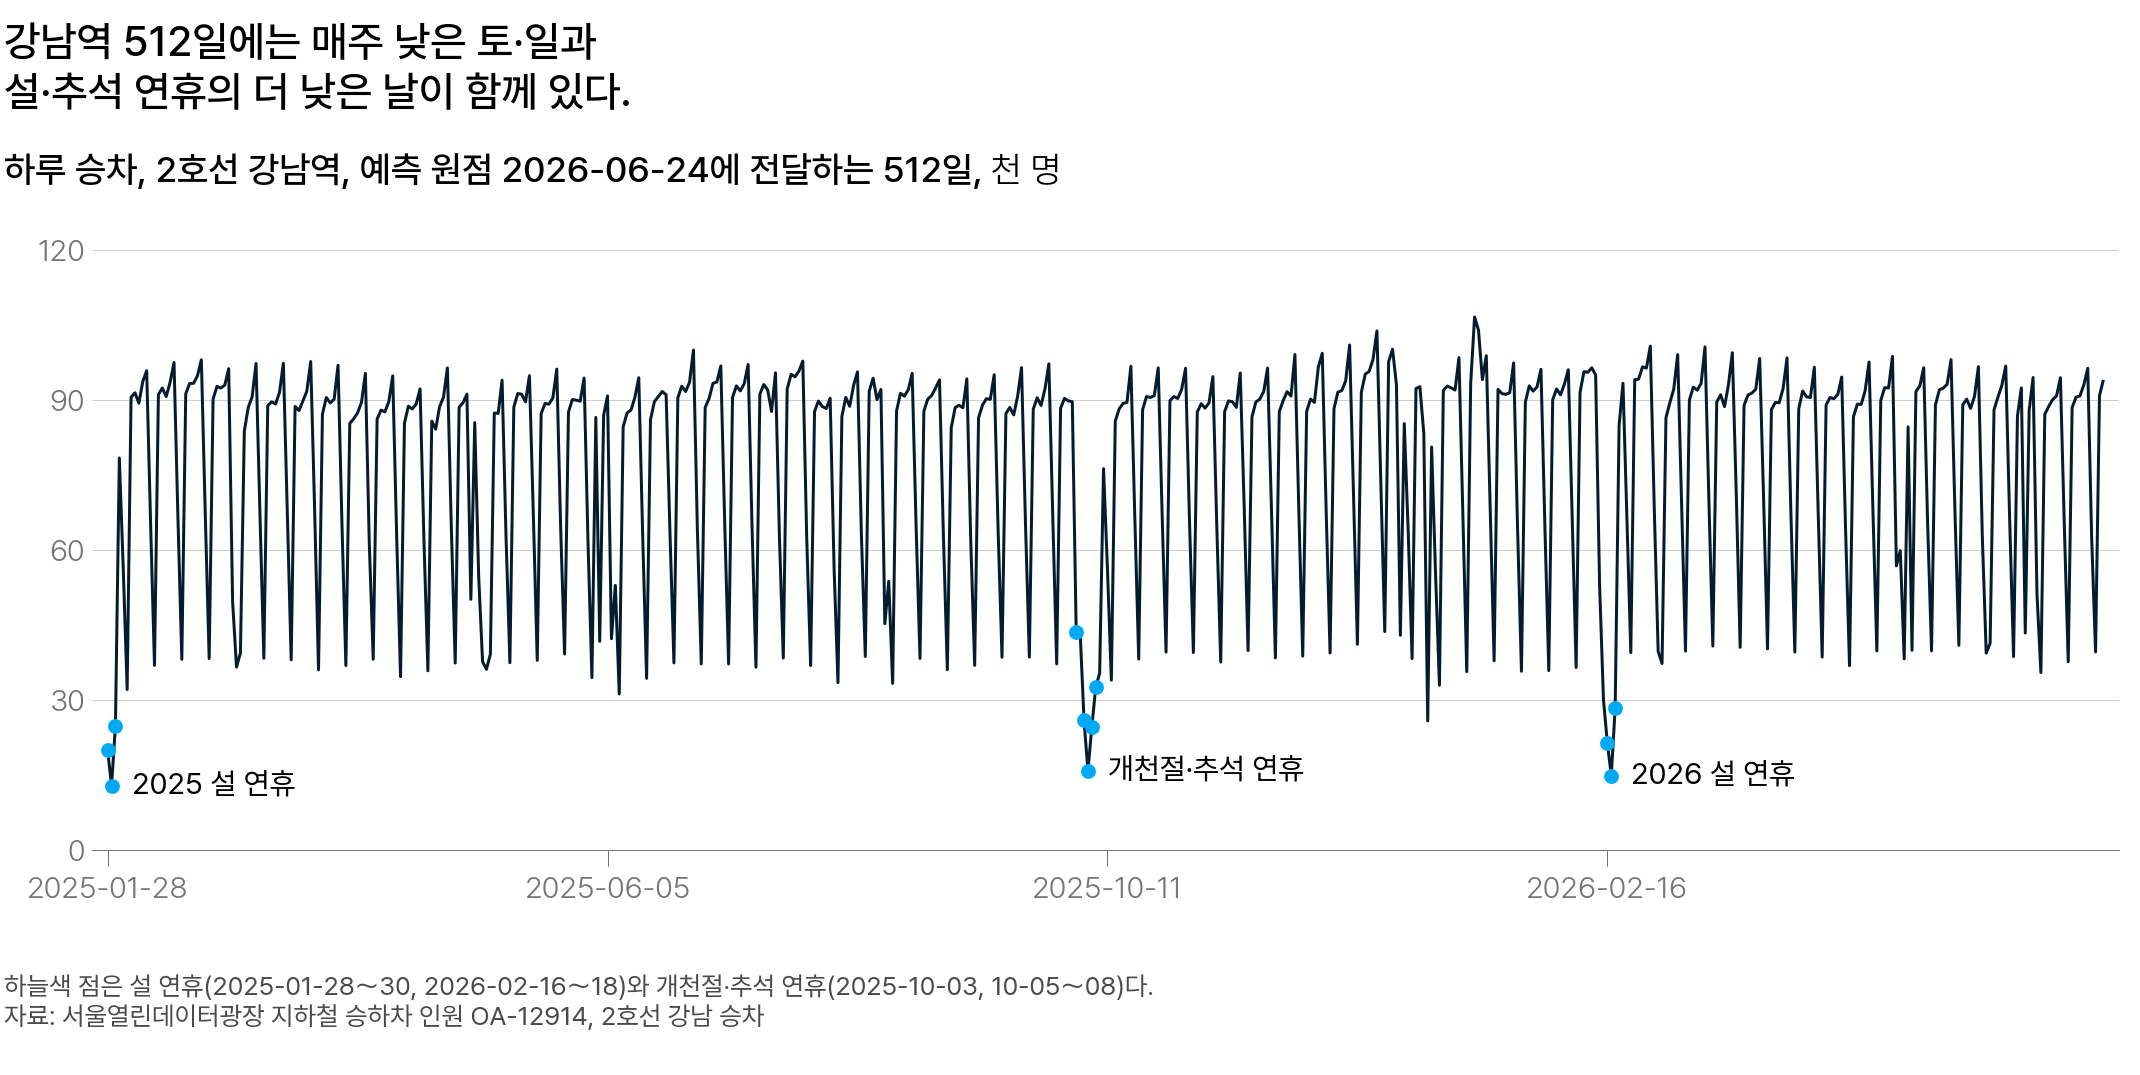

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 날짜, 세로축은 강남역 하루 승차(천 명)다. 원점 2026-06-24 에 모델에 전달하는 512일(2025-01-28～2026-06-23)이고, 남색 선이 승차, 하늘색 점은 설·추석 연휴와 개천절이다</em></p>

선이 매주 아래로 꺾이는 곳이 토·일입니다.

하늘색 점은 지난 설·추석 연휴와 개천절입니다. 이 날들은 낮은 승차 값으로만 입력에 있습니다.

| 요일 | 입력 512일의 요일 평균 | 예측한 날의 `"0.5"` 열 |
|---|---:|---:|
| 토요일 | 63,891명 | 06-27 67,342명 |
| 일요일 | 37,458명 | 06-28 39,453명 |

Chronos-2 의 가중치는 서울 지하철 자료로 고친 적이 없습니다. 그래서 토·일 예측이 낮은 까닭은 입력에만 있습니다.

**강남역의 요일 모양은 가중치가 아니라 입력 512일에서 옵니다.**

### 강남역 7일 예측은 얼마나 빗나갔나 [선택]

0.5 분위수 예측은 7일 동안 하루 평균 569명 빗나갔습니다.

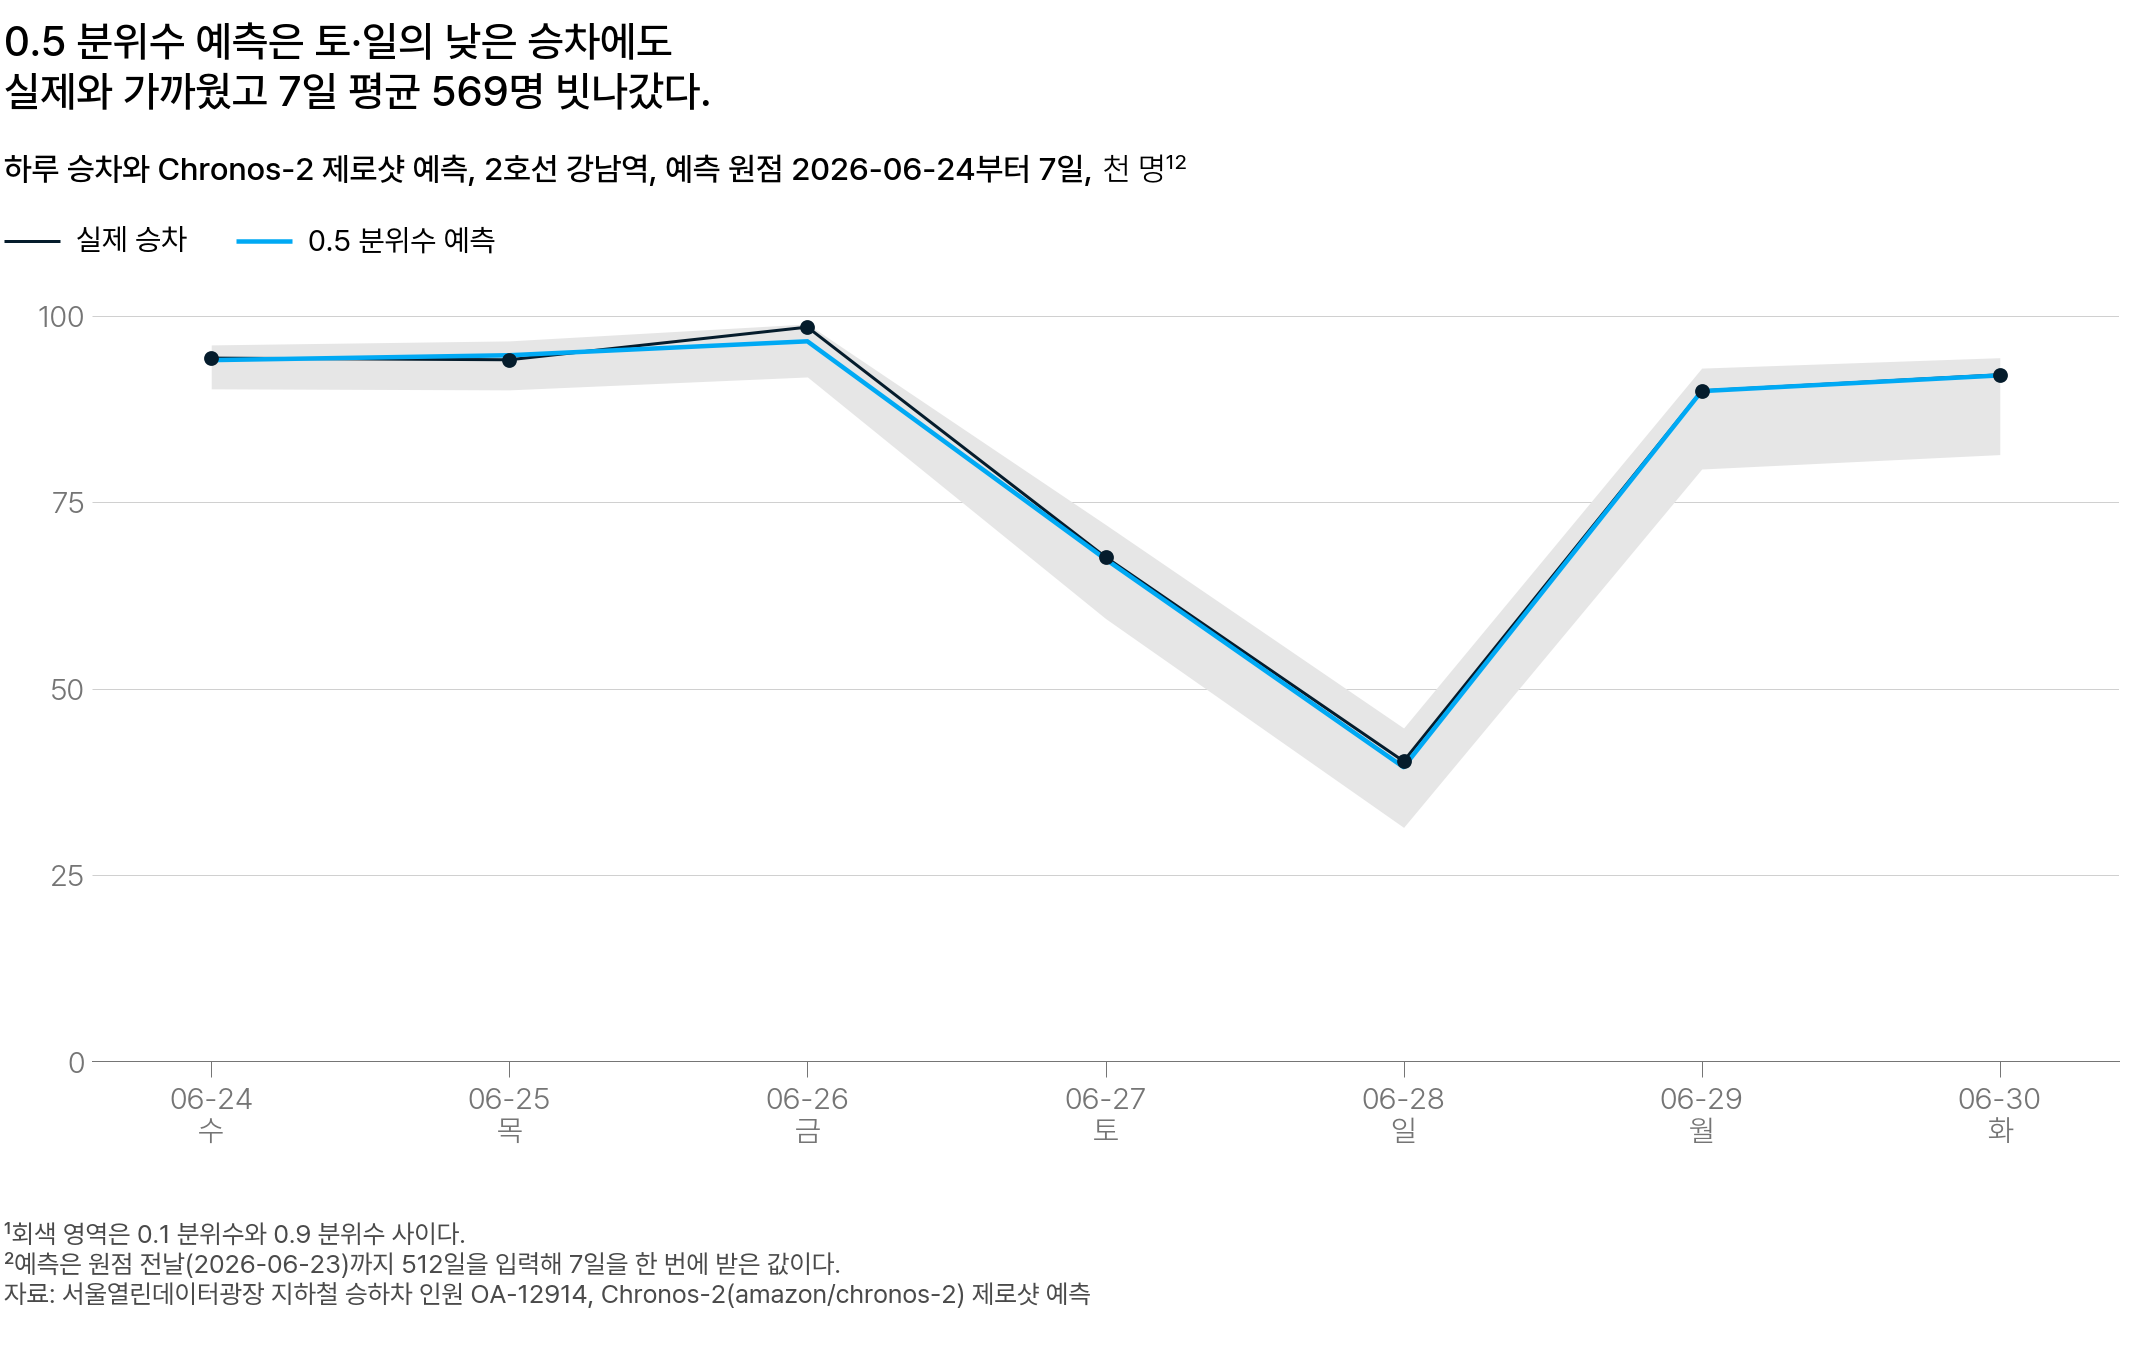

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 원점 2026-06-24(수)부터 7일, 세로축은 강남역 하루 승차(천 명)다. 남색 선이 실제 승차, 하늘색 선이 Chronos-2 제로샷 0.5 분위수 예측이고, 회색 영역은 0.1～0.9 분위수 사이다</em></p>

토·일의 낮은 승차까지 하늘색 선이 실제 승차 선과 거의 겹칩니다.

아래 코드는 이 7일의 평균 절대 오차와 MASE 를 계산합니다.

MASE 는 평균 절대 오차를 강남역의 MASE 분모 7,813.8명으로 나눈 값입니다. 7,813.8명은 원점 전날까지 계절 나이브가 강남역에서 빗나간 크기의 평균이고, 코드 이름은 `QDEN` 입니다.

In [ ]:
# 강남역 원점 2026-06-24 — Chronos-2 제로샷 7일 예측의 평균 절대 오차와 MASE(예측은 평가표 계산에서 옮긴 0.5 분위수)
import numpy as np

actual = np.array([94303, 94077, 98456, 67630, 40248, 89909, 92064])   # 06-24～06-30 실제 승차(명)
point = np.array([94030, 94683, 96552, 67342, 39453, 89875, 91981])    # 같은 7일의 0.5 분위수 예측(명)
mae = np.abs(actual - point).mean()

print(f"7일 평균 절대 오차 {mae:,.0f}명 → MASE {mae / 7813.8:.3f} (강남 MASE 분모 QDEN 7,813.8명으로 나눈 값)")

# 본문의 수와 같은지 확인
assert round(mae) == 569 and round(mae / 7813.8, 3) == 0.073

같은 7일의 하루 평균 절대 오차를 계절 나이브와 비교합니다.

| 방식 | 7일 평균 절대 오차 | MASE | 어디서 온 수인가 |
|---|---:|---:|---|
| Chronos-2 제로샷 | 569명 | 0.073 | 위 코드의 출력 |
| 계절 나이브 | 2,157명 | 0.276 | 1주일 전 같은 요일 값으로 같은 계산(아래 「자세히」) |

**이 주의 강남역에서는 제로샷이 계절 나이브의 4분의 1쯤만 빗나갔습니다.**

한 역, 한 주의 결과이므로 100개 역과 원점 5개로 넓혀 봅니다.

<details class="lms-extra"><summary>자세히 — 강남역 MASE 0.073 을 얻는 계산</summary>

강남역 원점 2026-06-24 의 7일을 하루씩 적으면 이렇습니다(단위: 명). 빗나간 크기는 실제와 예측의 차의 절댓값입니다. 계절 나이브는 1주일 전 같은 요일(06-17～06-23)의 실제 승차를 예측값으로 씁니다.

| 날짜 | 실제 승차 | 제로샷 0.5 분위수 | 제로샷이 빗나간 크기 | 계절 나이브 | 계절 나이브가 빗나간 크기 |
|---|---:|---:|---:|---:|---:|
| 06-24(수) | 94,303 | 94,030 | 273 | 90,908 | 3,395 |
| 06-25(목) | 94,077 | 94,683 | 606 | 93,111 | 966 |
| 06-26(금) | 98,456 | 96,552 | 1,904 | 96,421 | 2,035 |
| 06-27(토) | 67,630 | 67,342 | 288 | 62,555 | 5,075 |
| 06-28(일) | 40,248 | 39,453 | 795 | 39,693 | 555 |
| 06-29(월) | 89,909 | 89,875 | 34 | 90,946 | 1,037 |
| 06-30(화) | 92,064 | 91,981 | 83 | 94,098 | 2,034 |

제로샷이 빗나간 크기 일곱 개를 더하면 3,983명이고, 7로 나누면 하루 평균 569명입니다. 계절 나이브는 더하면 15,097명, 하루 평균 2,157명입니다.

하루 평균 오차를 강남역의 MASE 분모 $Q_i$(코드 이름 `QDEN`) 7,813.8명으로 나눕니다.

$$
\begin{aligned}
\text{제로샷:}\quad & 569 \div 7{,}813.8 = 0.073 \\
\text{계절 나이브:}\quad & 2{,}157 \div 7{,}813.8 = 0.276
\end{aligned}
$$

그래서 이 주의 강남역에서는 제로샷의 하루 평균 오차가 MASE 분모의 10분의 1 도 되지 않았습니다.

</details>

### 100개 역 평가표에 더하면 [필수]

원점 5개마다 Chronos-2 제로샷에 512일을 입력해 7일 예측을 받고, `"0.5"` 열을 채점했습니다.

> **[예측] 공휴일 없는 두 주와 공휴일 있는 세 주에서 Chronos-2 제로샷의 MASE 는 계절 나이브보다 낮을까요?**
>
> 1. 공휴일이 있는 주와 없는 주 모두 계절 나이브보다 낮다
> 2. 공휴일 없는 두 주에서만 계절 나이브보다 낮다
> 3. 공휴일이 있는 주와 없는 주 모두 계절 나이브와 비슷하다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

둘째 보기가 맞습니다. 마지막 행이 새로 더한 값입니다.

| 방식 | 평균 MASE | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|---:|
| 계절 나이브 | 1.838 | 0.445 | 2.767 |
| 직전 7일 평균 | 2.984 | 1.935 | 3.684 |
| 글로벌 MLP(MSE 손실) | 1.848 | 0.739 | 2.587 |
| 글로벌 MLP(MAE 손실) | 1.774 | 0.359 | 2.717 |
| **Chronos-2 제로샷** | **1.766** | **0.271** | **2.763** |

공휴일 없는 두 주에는 0.271 로 다섯 방식 가운데 가장 낮습니다.

공휴일 있는 세 주에는 2.763 으로 계절 나이브와 거의 같습니다.

MASE 1 이 평소 빗나가던 크기라, 2.763 은 그 두 배가 넘습니다. 그래서 공휴일 있는 세 주에는 이 예측을 그대로 쓰지 않습니다.

**공휴일 없는 두 주에서만 제로샷의 MASE 가 계절 나이브보다 낮습니다.**

<details class="lms-extra"><summary>자세히 — 0.9 열이나 0.1 열을 점 예측으로 쓰면</summary>

같은 제로샷 예측에서 점 예측 열만 바꿔 공휴일 없는 두 주를 채점했습니다. 역·날 1,400개(원점 2개 × 역 100개 × 7일) 가운데 실제보다 낮게 예측한 역·날의 비율도 함께 셉니다.

| 점 예측으로 쓴 열 | 공휴일 없는 두 주 MASE | 실제보다 낮게 예측한 역·날 |
|---|---:|---:|
| `"0.1"` | 0.810 | 99.4% |
| `"0.5"` | 0.271 | 62.9% |
| `"0.9"` | 0.459 | 14.3% |

0.1 열은 거의 모든 날을 실제보다 낮게, 0.9 열은 대부분의 날을 실제보다 높게 예측합니다. 두 열 모두 한쪽으로 치우쳐 절대 오차가 커지고, MASE 도 0.5 열보다 큽니다.

0.5 열은 실제가 그 값 이하일 확률이 50% 가 되게 계산한 값이라, 실제보다 낮게 예측한 역·날도 50% 쯤일 것으로 예상합니다. 그런데 62.9% 인 것은 100개 역이 같은 날 함께 오르내리기 때문입니다. 그날 승차가 여러 역에서 함께 예측보다 조금 많으면, 그날은 대부분의 역을 실제보다 낮게 예측한 셈이 됩니다. 역·날은 1,400개여도 채점하는 날은 14일뿐이라, 이렇게 한쪽으로 몰린 날이 반반으로 상쇄되지 않습니다.

공휴일 없는 두 주의 14일을 날마다 보면, 0.5 열이 실제보다 낮은 역이 절반을 넘는 날이 10일(가장 많은 날은 06-27 토요일, 86개 역)입니다. 절반보다 적은 날은 3일(가장 적은 날은 06-25 목요일, 19개 역), 딱 절반인 날은 1일입니다. 낮게 잡은 크기는 작아서, 날마다 100개 역 예측 합은 실제 합의 0.97～1.01배였습니다.

그래서 MASE 로 채점하는 평가표에는 0.5 열을 적습니다. 0.9 열 값에 맞춰 인력을 두는 것은 다른 결정입니다. 인력이 모자랄 때의 비용이 남을 때의 비용보다 클 때 따집니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 예측 원점 다섯 개로 나눠 본 MASE</summary>

평가표 값의 바탕이 된 원점별 MASE 입니다. 평균 MASE 는 이 다섯 값의 평균이고, 공휴일 없는 두 주와 있는 세 주의 값은 원점 2개 · 3개의 평균입니다.

| 방식 | 2025-08-13 | 2025-10-01 | 2025-12-10 | 2026-02-11 | 2026-06-24 |
|---|---:|---:|---:|---:|---:|
| 계절 나이브 | 1.069 | 4.388 | 0.419 | 2.844 | 0.471 |
| 직전 7일 평균 | 2.180 | 4.881 | 1.919 | 3.991 | 1.950 |
| 글로벌 MLP(MSE 손실) | 1.062 | 4.047 | 0.536 | 2.653 | 0.943 |
| 글로벌 MLP(MAE 손실) | 1.067 | 4.322 | 0.326 | 2.762 | 0.393 |
| Chronos-2 제로샷 | 1.115 | 4.238 | 0.279 | 2.935 | 0.263 |

공휴일 없는 두 주(2025-12-10 · 2026-06-24)에서는 두 주 모두 제로샷이 다섯 방식 가운데 가장 낮습니다. 공휴일 있는 세 주에서는 다섯 방식 모두 1 을 넘고, 원점 2025-10-01 에서는 가장 낮은 MLP(MSE 손실)도 4.047 입니다.

두 MLP 는 CPU 에서 시드 0 으로 한 번 학습한 값이라, 기기와 시드가 바뀌면 달라집니다. 첫날 글로벌 MLP(MSE 손실)는 시드 0～4 에서 원점 2026-06-24 의 MASE 가 0.553～0.943 이었습니다. 제로샷은 학습하지 않아 같은 기기에서 다시 불러도 같은 값입니다.

원점 2025-08-13 은 광복절 앞 이틀 08-13·14 에 제로샷이 계절 나이브보다 더 빗나갔고, 뒤에서 볼 역 비율도 34% 입니다.

그래서 제로샷이 앞서는 곳은 공휴일 없는 두 주이고, 공휴일 있는 세 주에서는 어느 방식도 인력 계획에 그대로 쓸 만큼 낮지 않습니다.

</details>

### 계절 나이브의 몇 배만큼 빗나갔나 [선택]

제로샷의 MASE 는 공휴일 없는 두 주에 계절 나이브의 0.61배이고, 공휴일 있는 세 주에 1.00배입니다.

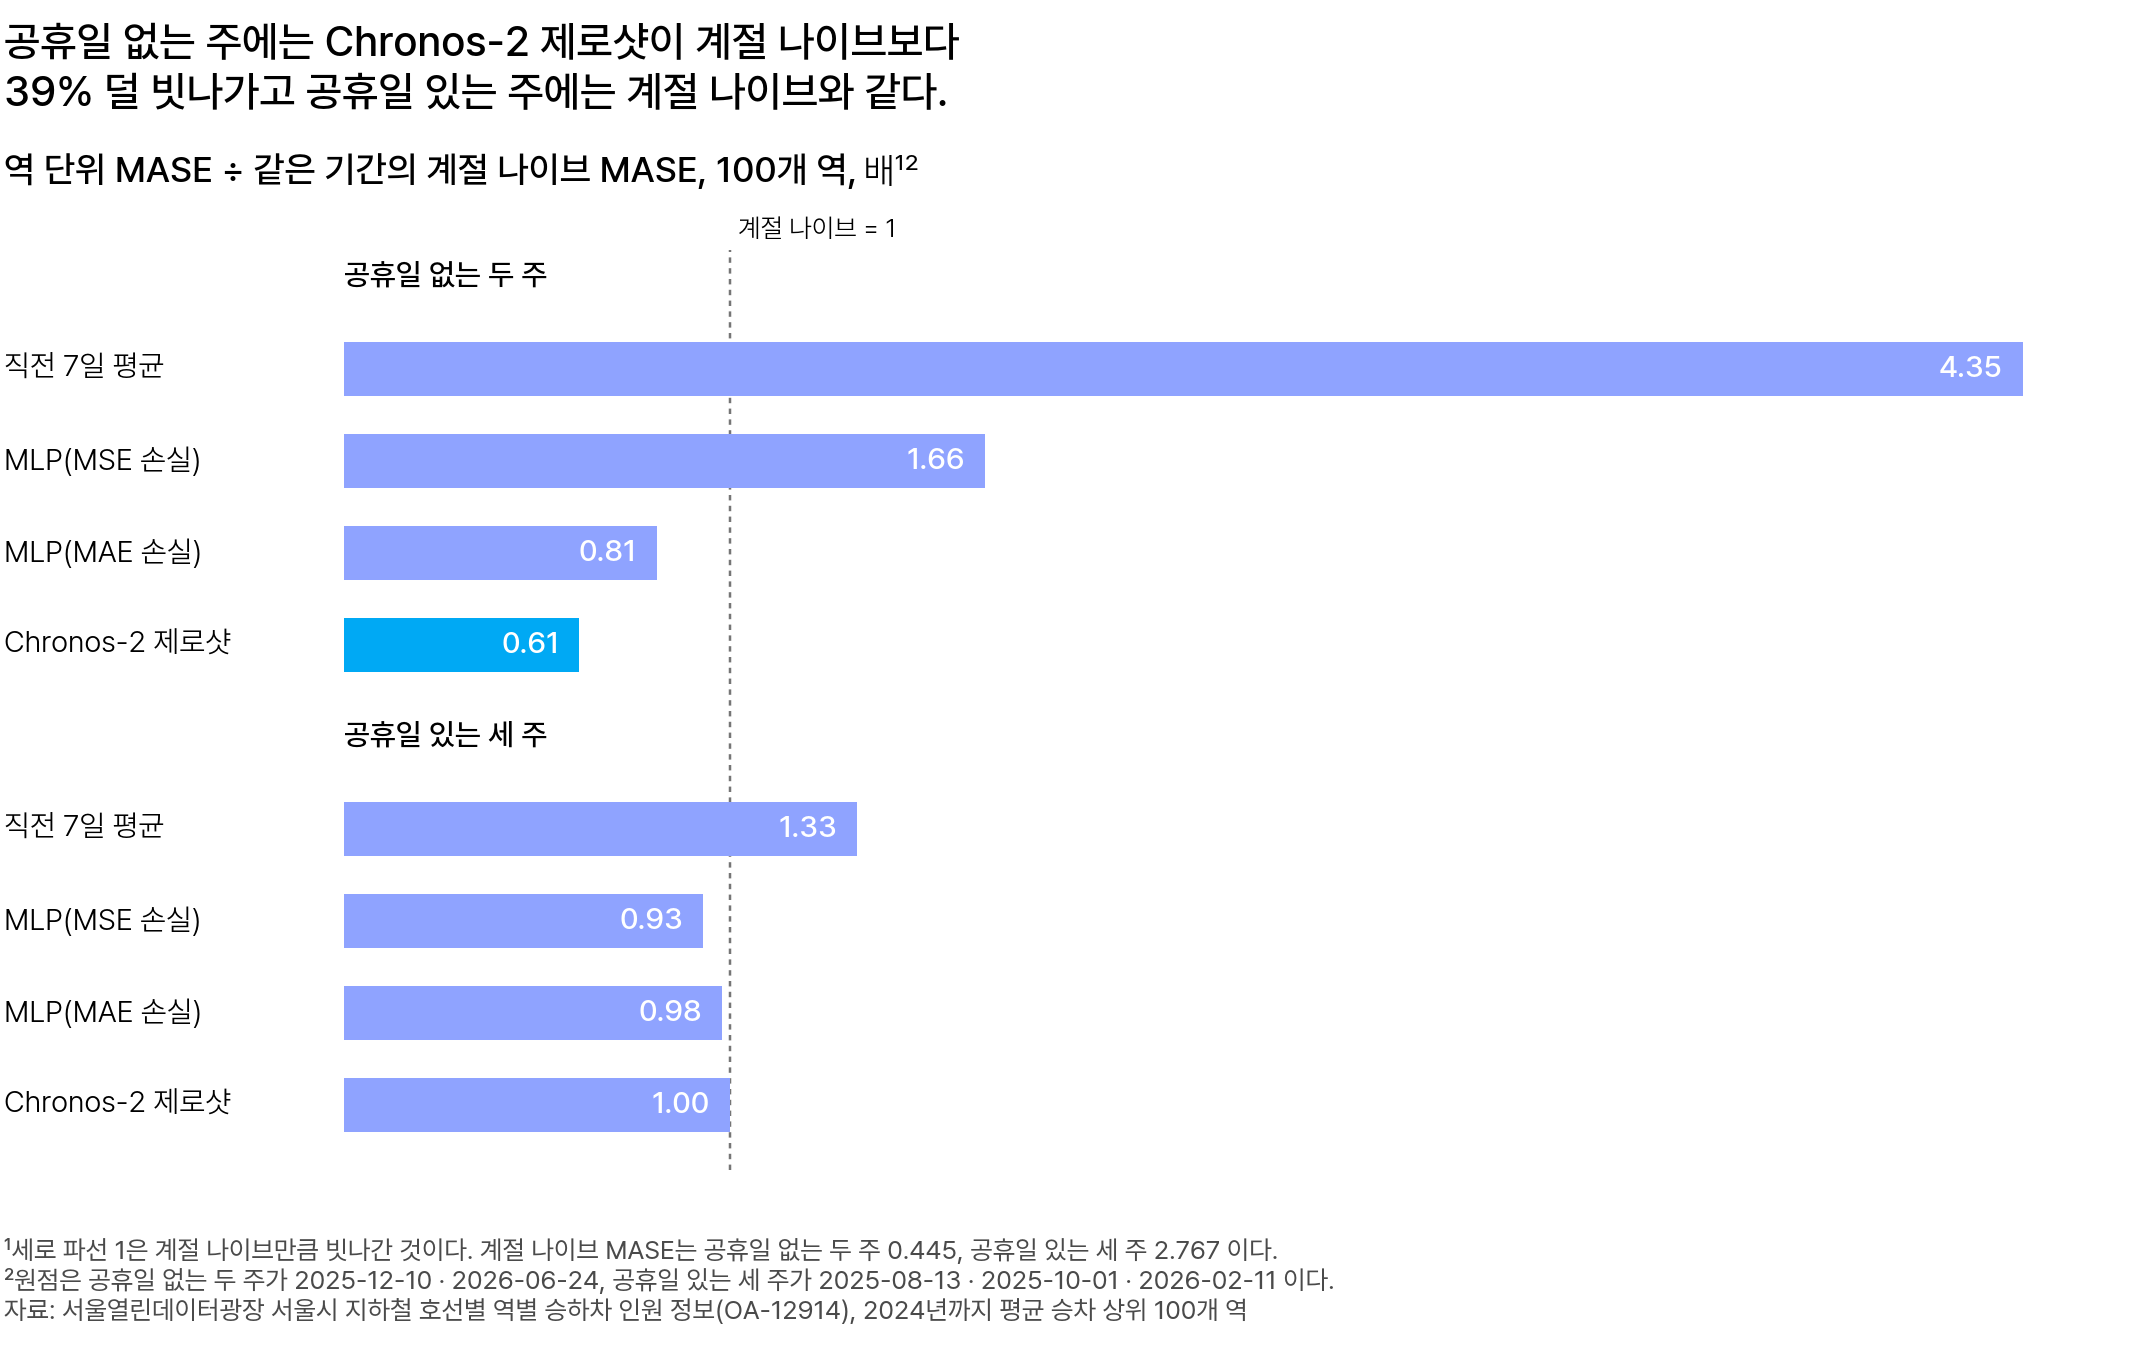

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 같은 기간의 계절 나이브 대비 배수다. 평가표 다섯 방식 가운데 계절 나이브를 뺀 네 방식의 역 단위 MASE 를 같은 기간의 계절 나이브 MASE 로 나눈 값이다. 위는 공휴일 없는 두 주, 아래는 공휴일 있는 세 주다. 회색 세로 파선 1 은 계절 나이브만큼 빗나간 것이다. 하늘색 막대가 공휴일 없는 두 주의 Chronos-2 제로샷이다</em></p>

0.61배는 0.271 ÷ 0.445 로, 계절 나이브보다 39% 덜 빗나갔다는 뜻입니다.

1.00배는 계절 나이브만큼 빗나갔다는 뜻입니다.

**공휴일 있는 세 주에는 제로샷도 계절 나이브만큼 크게 빗나가, 그대로 쓰지 않습니다.**

### 평가표의 차를 모델 차이로 읽어도 되나 [필수]

평가표의 두 값을 뺀 차를 시드 범위 0.077 과 비교합니다.

| 비교(평가표의 값) | 차 | 0.077 보다 | 읽는 법 |
|---|---:|---|---|
| 공휴일 없는 두 주: 계절 나이브 0.445 − 제로샷 0.271 | 0.174 | 크다 | 제로샷이 낮다 |
| 공휴일 없는 두 주: MLP(MAE 손실) 0.359 − 제로샷 0.271 | 0.088 | 조금 넘는다 | 시드 다섯 값을 함께 보면 제로샷이 낮다 |
| 공휴일 있는 세 주: 계절 나이브 2.767 − 제로샷 2.763 | 0.004 | 작다 | 같다 |
| 원점 5개 평균: MLP(MAE 손실) 1.774 − 제로샷 1.766 | 0.008 | 작다 | 순위를 말하지 않는다 |

공휴일 없는 두 주와 공휴일 있는 세 주의 평균은 원점 2개·3개만 평균한 값이라 시드마다 더 크게 달라집니다. 그래서 조금 넘는 차는 다른 근거와 함께 읽습니다.

둘째 행에서 함께 본 근거는 MLP(MAE 손실)를 시드 0～4 로 다시 학습한 다섯 값입니다. 다섯 값 모두 제로샷보다 높았습니다.

**공휴일 없는 두 주에는 제로샷이 낮고, 공휴일 있는 세 주와 평균으로는 차이를 말하지 않습니다.**

<details class="lms-extra"><summary>자세히 — 조금 넘는 차를 시드 다섯 값으로 확인하면</summary>

첫날 MLP(MSE 손실)를 공휴일 없는 두 주만 평균하면 시드 0～4 에서 0.571～0.739 입니다. 공휴일 없는 두 주 평균의 시드 범위는 0.739 − 0.571 = 0.168 입니다.

둘째 행의 0.088 은 0.077 은 넘지만 0.168 보다 작습니다. 그래서 시드 다섯 값을 함께 봤습니다.

MLP(MAE 손실)는 시드 0～4 에서 공휴일 없는 두 주가 0.356～0.372 였습니다. 다섯 값 모두 제로샷 0.271 보다 높아, 둘째 행도 제로샷이 낮다고 적습니다.

첫 행의 0.174 는 0.168 보다도 큽니다. 그래서 다른 근거 없이 제로샷이 낮다고 읽었습니다.

</details>

### 역마다 비교하면 무엇이 보이나 [필수]

평균은 크게 빗나간 역 하나로도 달라지므로, 새 모델이 덜 빗나간 역이 몇 개인지 봅니다.

**계절 나이브보다 MASE 가 낮은 역 비율(percent better)** 은 원점 하나에서 역마다 두 모델의 MASE 를 비교한 비율입니다.

100개 역 가운데 새 모델의 MASE 가 더 낮은 역의 수가 곧 비율(%)입니다. 50% 면 반반이고, 90% 면 열 역 가운데 아홉에서 덜 빗나간 것입니다.

역 넷으로 간단히 계산해 봅니다.

| 역(예) | 가 | 나 | 다 | 라 | 평균 |
|---|---:|---:|---:|---:|---:|
| 새 모델의 MASE | 0.3 | 0.3 | 0.3 | 2.0 | 0.725 |
| 계절 나이브의 MASE | 0.4 | 0.4 | 0.4 | 0.8 | 0.5 |

평균은 새 모델이 더 크지만, 역 넷 가운데 셋(75%)에서는 새 모델이 덜 빗나갔습니다.

- **좋은 점**: 역 하나가 크게 빗나가도 그 역 하나로만 셉니다
- **약한 점**: 얼마나 덜 빗나갔는지는 담지 않습니다
- **이럴 때 쓴다**: 평균 MASE 차로 순위를 말할 수 없을 때, 새 모델을 원점마다 계절 나이브와 비교할 때

원점 2026-06-24 의 역별 MASE 를 비교하면 93개 역에서 제로샷이 더 낮았습니다. 강남역도 그 가운데 하나입니다.

**평균만으로는 보이지 않는 역별 결과를 역의 수로 봅니다.**

### 원점마다 MASE 가 낮은 역 비율은 얼마였나 [필수]

공휴일 없는 두 주는 89%·93% 이고, 공휴일 있는 세 주는 원점마다 다릅니다.

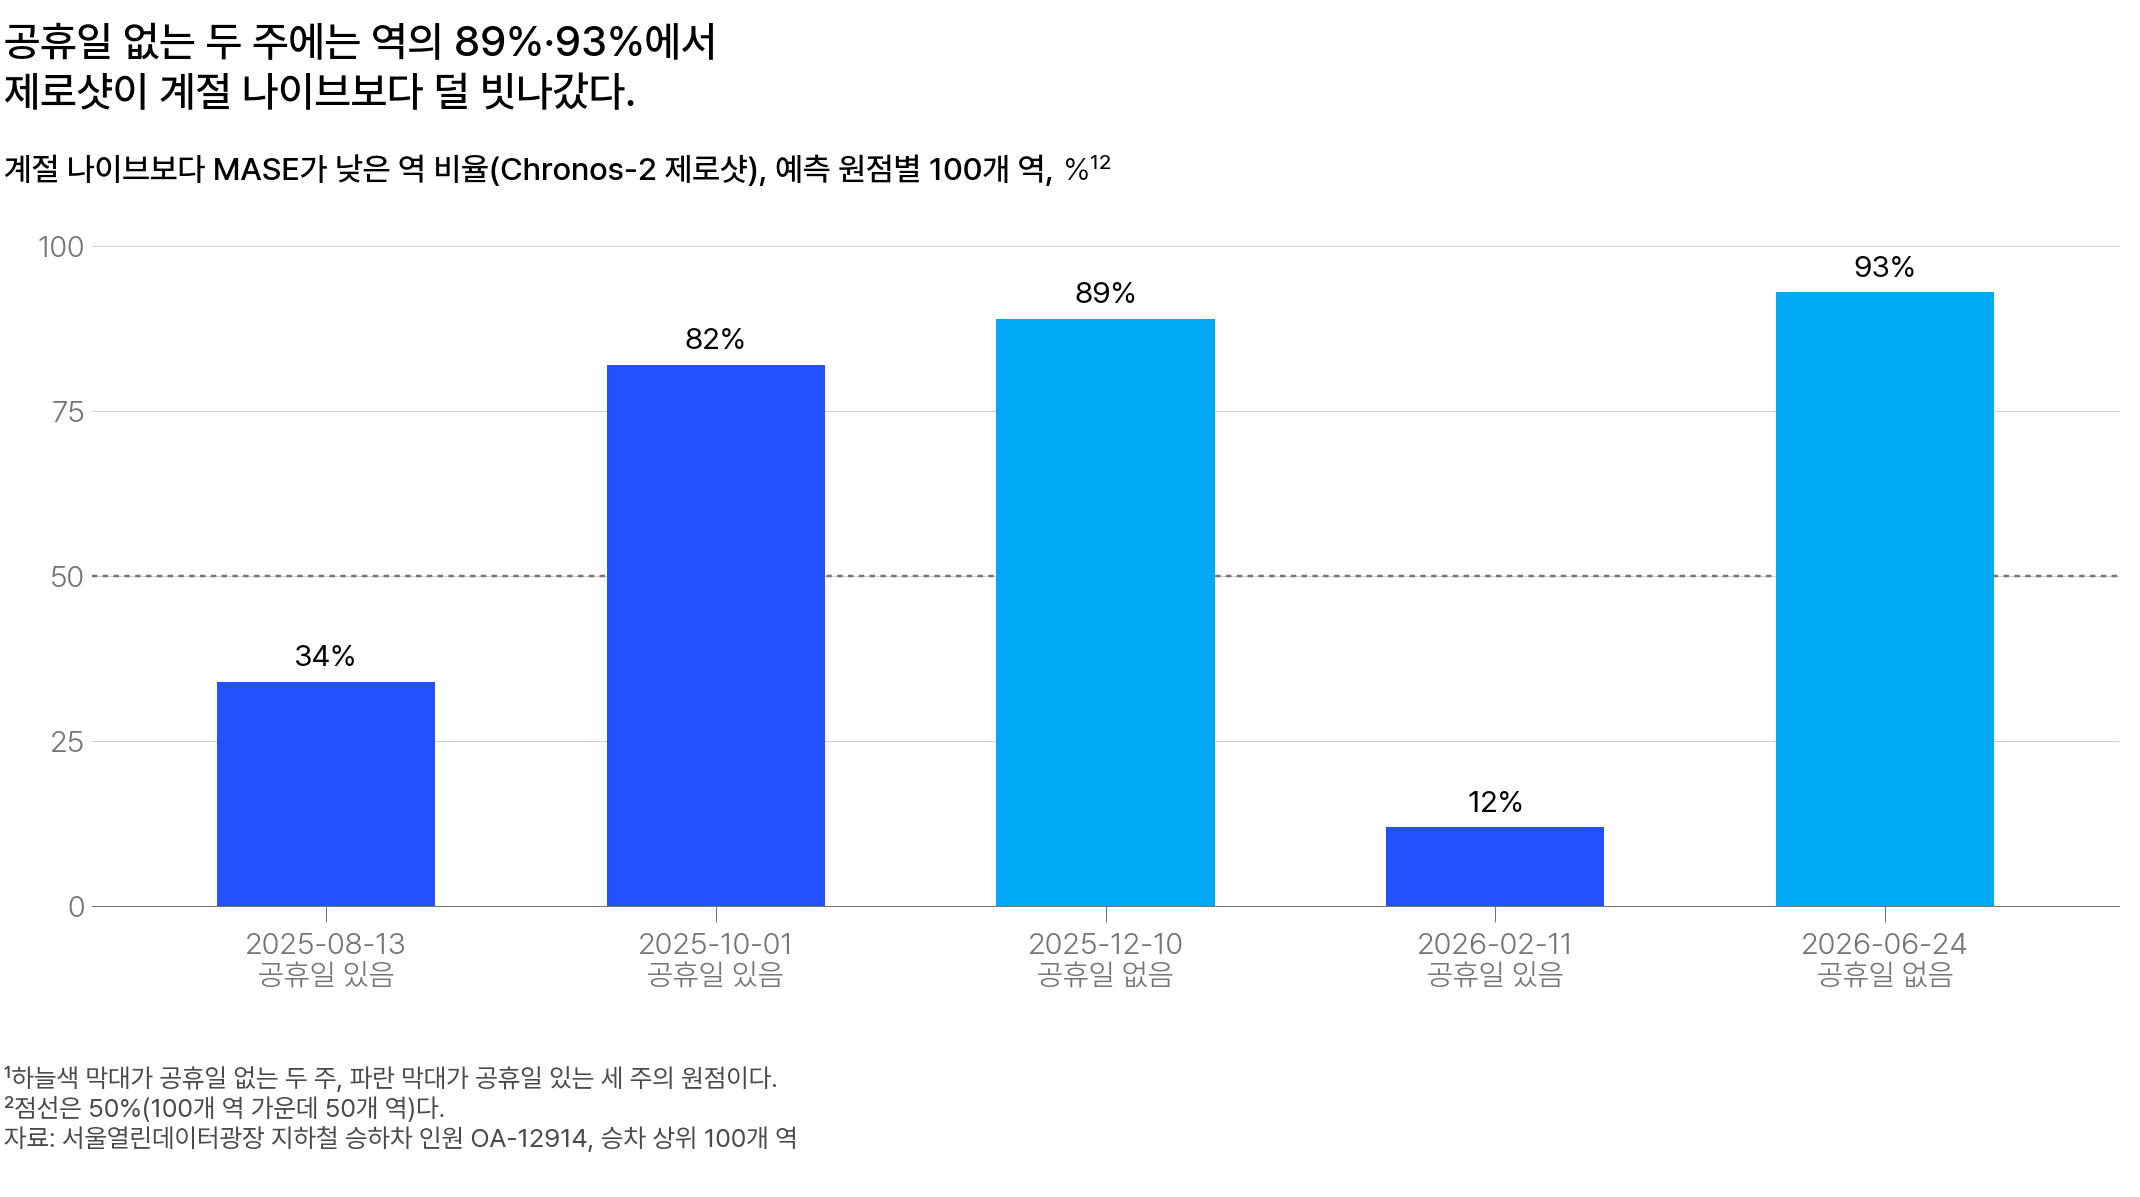

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 예측 원점, 세로축은 계절 나이브보다 MASE 가 낮은 역 비율(%), 곧 100개 역 가운데 Chronos-2 제로샷의 MASE 가 더 낮은 역의 비율이다. 하늘색 막대가 공휴일 없는 두 주의 원점이고, 점선이 50% 다</em></p>

50% 아래인 원점은 둘이고, 둘 다 공휴일 있는 주입니다.

| 원점 | 비율 | 제로샷이 더 빗나간 날 |
|---|---:|---|
| 2025-08-13 | 34% | 광복절 앞 이틀 08-13·14 |
| 2026-02-11 | 12% | 설 연휴 앞 주말 02-14·15 |

설 연휴 앞 주말에는 실제 승차가 1주일 전보다 줄었습니다. 1주일 전 값을 쓰는 계절 나이브도 실제보다 높았고, 제로샷은 그보다 더 높게 예측했습니다.

82% 인 원점 2025-10-01 은 두 방식 모두 MASE 가 4 를 넘은 주입니다. 비율이 높아도 이 주에 쓸 만하다는 뜻은 아닙니다.

**공휴일 없는 두 주에는 대부분의 역에서 제로샷의 MASE 가 낮고, 공휴일 있는 세 주는 원점마다 다릅니다.**

> **[문제] 원점 2026-02-11 의 12% 를 보고서에 적기**
>
> 원점 2026-02-11 에서 Chronos-2 제로샷이 계절 나이브보다 MASE 가 낮은 역은 12개(12%)였습니다. 공휴일 없는 두 주는 89%·93% 였습니다. 운영팀 보고서에 이 원점을 어떻게 적을까요?

### 미세조정을 해 보면 [필수]

100개 역으로 더 학습해도 평균 MASE 는 0.009 만 줄었습니다.

미세조정은 사전학습 가중치에서 출발해 서울 지하철 100개 역으로 몇 스텝 더 학습하는 것입니다.

| 값 | 수 | 어디서 온 수인가 |
|---|---:|---|
| 제로샷 평균 MASE | 1.766 | 평가표 |
| 미세조정 뒤 평균 MASE | 1.757 | 같은 원점 5개를 미세조정한 Chronos-2 로 다시 채점 |
| 줄어든 크기 | 0.009 | 1.766 − 1.757 |
| 시드 범위 | 0.077 | 「MASE 차가 얼마나 커야 모델 차이로 읽나」 |
| 원점마다 학습 시간 | 0초 대 평균 446초 | 제로샷 대 미세조정(맥 CPU 실측) |
| 제로샷의 예측 시간 | 1초 안쪽 | 원점 하나의 100개 역, Colab T4 실측(0.27～0.61초) |

줄어든 0.009 는 시드 범위 0.077 보다 작습니다.

제로샷은 학습 없이 예측에 1초 안쪽이 들고, 미세조정은 원점마다 학습에 평균 446초가 더 듭니다.

**그래서 0.009 를 모델 차이로 읽지 않고, 평가표에 미세조정을 더하지 않습니다.**

<details class="lms-extra"><summary>자세히 — 미세조정을 어떻게 실행했고 공휴일이 있는 주와 없는 주에서 어땠나</summary>

미세조정은 원점마다 한 스텝에 윈도 64개를 읽으며 100스텝까지 학습했습니다. 윈도 하나는 역 하나의 승차에서 무작위로 잘라 낸 입력 구간과 그 바로 뒤 값입니다.

25스텝마다 원점 직전 56일(검증 구간)의 손실을 재고, 손실이 가장 작은 스텝의 가중치로 예측했습니다. 손실이 가장 작은 스텝은 원점 5개 가운데 넷에서 100스텝, 원점 2025-10-01 에서 25스텝이었습니다. 첫날 MLP 의 조기 종료와 같은 방법이고, 에폭 대신 25스텝 단위로 골랐습니다.

공휴일이 있는 주와 없는 주로 나눠 보면 이렇습니다. 차는 미세조정 뒤 값에서 제로샷 값을 뺀 값입니다.

| 채점한 주 | 제로샷 | 미세조정 뒤 | 차 |
|---|---:|---:|---:|
| 공휴일 없는 두 주 | 0.271 | 0.279 | +0.008 |
| 공휴일 있는 세 주 | 2.763 | 2.743 | −0.020 |

둘 다 시드 범위 0.077 보다 작고, 방향도 같지 않습니다.

미세조정은 시드 0 으로 한 번만 실행했습니다. 그래서 시드만 바꿔 다시 학습한 첫날 글로벌 MLP 의 값을 참고값으로 씁니다.

MLP(MAE 손실)의 원점 5개 평균은 시드 0～4 에서 1.774～1.790 이라 시드 범위가 0.016 입니다. 두 MLP 가운데 시드 범위가 더 큰 MLP(MSE 손실)의 0.077 을 기준으로 삼았습니다.

첫날 글로벌 MLP(MAE 손실)를 처음부터 학습하는 데는 맥 CPU 에서 원점마다 평균 17초가 들었습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 컨텍스트를 128일로 줄이면</summary>

컨텍스트 길이만 512일에서 128일로 줄여 같은 원점 5개를 다시 채점했습니다. 가중치는 그대로이고, 전달하는 과거만 짧아집니다.

| 컨텍스트 | 평균 MASE | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|---:|
| 512일 | 1.766 | 0.271 | 2.763 |
| 128일 | 1.768 | 0.324 | 2.731 |

공휴일 없는 두 주는 0.271 에서 0.324 로 0.053 커집니다. 공휴일 있는 세 주는 2.763 에서 2.731 로 0.032 작아집니다. 제로샷은 학습이 없어, 512일로도 128일로도 다시 부르면 표의 값이 그대로 나옵니다. 평가표에는 처음 정한 512일 예측을 적고, 컨텍스트 길이를 바꿔 예측했다면 방식 이름에 그 길이를 함께 적습니다.

128일은 넉 달 남짓이고, 512일은 1년 넘게 거슬러 올라가 지난해 같은 달까지 담습니다. 그래도 원점이 공휴일 없는 주 2개, 공휴일 있는 주 3개뿐이고 변화 방향도 서로 반대입니다. 길이가 MASE 를 바꾸는지는 이 다섯 원점으로는 말할 수 없습니다.

</details>

### 사전학습 자료와 채점 기간이 겹치나 [필수]

공개일보다 늦은 원점 셋은 겹칠 수 없고, 앞선 원점 둘은 확인하지 못했습니다.

채점하는 주가 사전학습 자료에 들어 있었다면, 학습한 적 없는 주를 예측한 결과가 아닙니다.

Chronos-2 [기술 보고서](https://arxiv.org/abs/2510.15821)는 2025-10-17 에 공개되었고, 사전학습 자료는 공개 전에 모은 것입니다.

| 예측 원점 | 채점 7일은 공개일(2025-10-17)보다 | 사전학습 자료에 들어갔을 수 있나 |
|---|---|---|
| 2025-12-10 · 2026-02-11 · 2026-06-24 | 늦다 | 들어갈 수 없다 |
| 2025-08-13 · 2025-10-01 | 이르다 | 확인 못 함 |

보고서가 공개한 실제 자료 목록에 서울 지하철 자료는 없습니다. 확인하지 못한 두 원점은 모두 공휴일 있는 세 주입니다.

**공휴일 없는 두 주의 결과는 사전학습 자료와 겹칠 수 없습니다.**

<div class="lms-summary">

**정리**

공휴일 없는 두 주에는 두 주 평균으로도, 역마다 비교해도 제로샷의 MASE 가 계절 나이브보다 낮습니다. 공휴일 있는 세 주에는 같습니다. 미세조정은 평가표에 더하지 않습니다.

**할 일**

- 원점마다 제로샷이 계절 나이브보다 MASE 가 낮은 역의 비율을 평가표의 제로샷 옆에 적습니다
- 공개일보다 앞선 원점 2개(2025-08-13·2025-10-01)는 사전학습 자료와 겹쳤을 수 있다고 함께 적습니다
- 평균 MASE 차가 시드 범위 0.077 보다 작으면 평균으로 순위를 적지 않습니다

Chronos-2 제로샷은 공휴일 없는 주의 역별 인력 예측 후보로 올리고, 평일 공휴일이 있는 주에는 그대로 쓰지 않습니다.

</div>

> **[문제] 평균 MASE 1.766 과 1.774 의 차 0.008**
>
> Chronos-2 제로샷의 평균 MASE 는 1.766, 첫날 글로벌 MLP(MAE 손실)는 이 교재를 만든 환경(맥 CPU·시드 0)에서 1.774 입니다. 운영팀 보고서에 이 차 0.008 을 어떻게 적을까요?
>
> 1. 평균 하나로 순위를 말하지 않고, 공휴일이 있는 주와 없는 주의 평균과 원점마다 제로샷이 계절 나이브보다 MASE 가 낮은 역의 비율로 읽는다
> 2. 평균 MASE 가 1.766 으로 가장 낮으니, 운영팀 보고서에는 Chronos-2 제로샷을 가장 좋은 모델로 적는다
> 3. 차 0.008 이 1.766 의 0.5% 도 안 되니, 두 모델은 공휴일이 있는 주와 없는 주 모두에서 같은 성능이라고 적는다

## 5. 평일 공휴일 과대 예측

평일 공휴일이 있는 주의 역별 인력을 이 예측으로 정해도 될까요?

### 평일 공휴일에 예측은 얼마나 넘쳤나 [필수]

평일 공휴일 6일에는 100개 역의 예측 합이 실제 합의 2.14배였습니다.

공휴일 있는 세 주의 평일 15일마다 Chronos-2 제로샷의 예측 합을 실제 합으로 나눴습니다.

그 가운데 평일 공휴일이 6일입니다.

- 광복절: 08-15
- 개천절: 10-03
- 추석 연휴: 10-06·07
- 설 연휴: 02-16·17

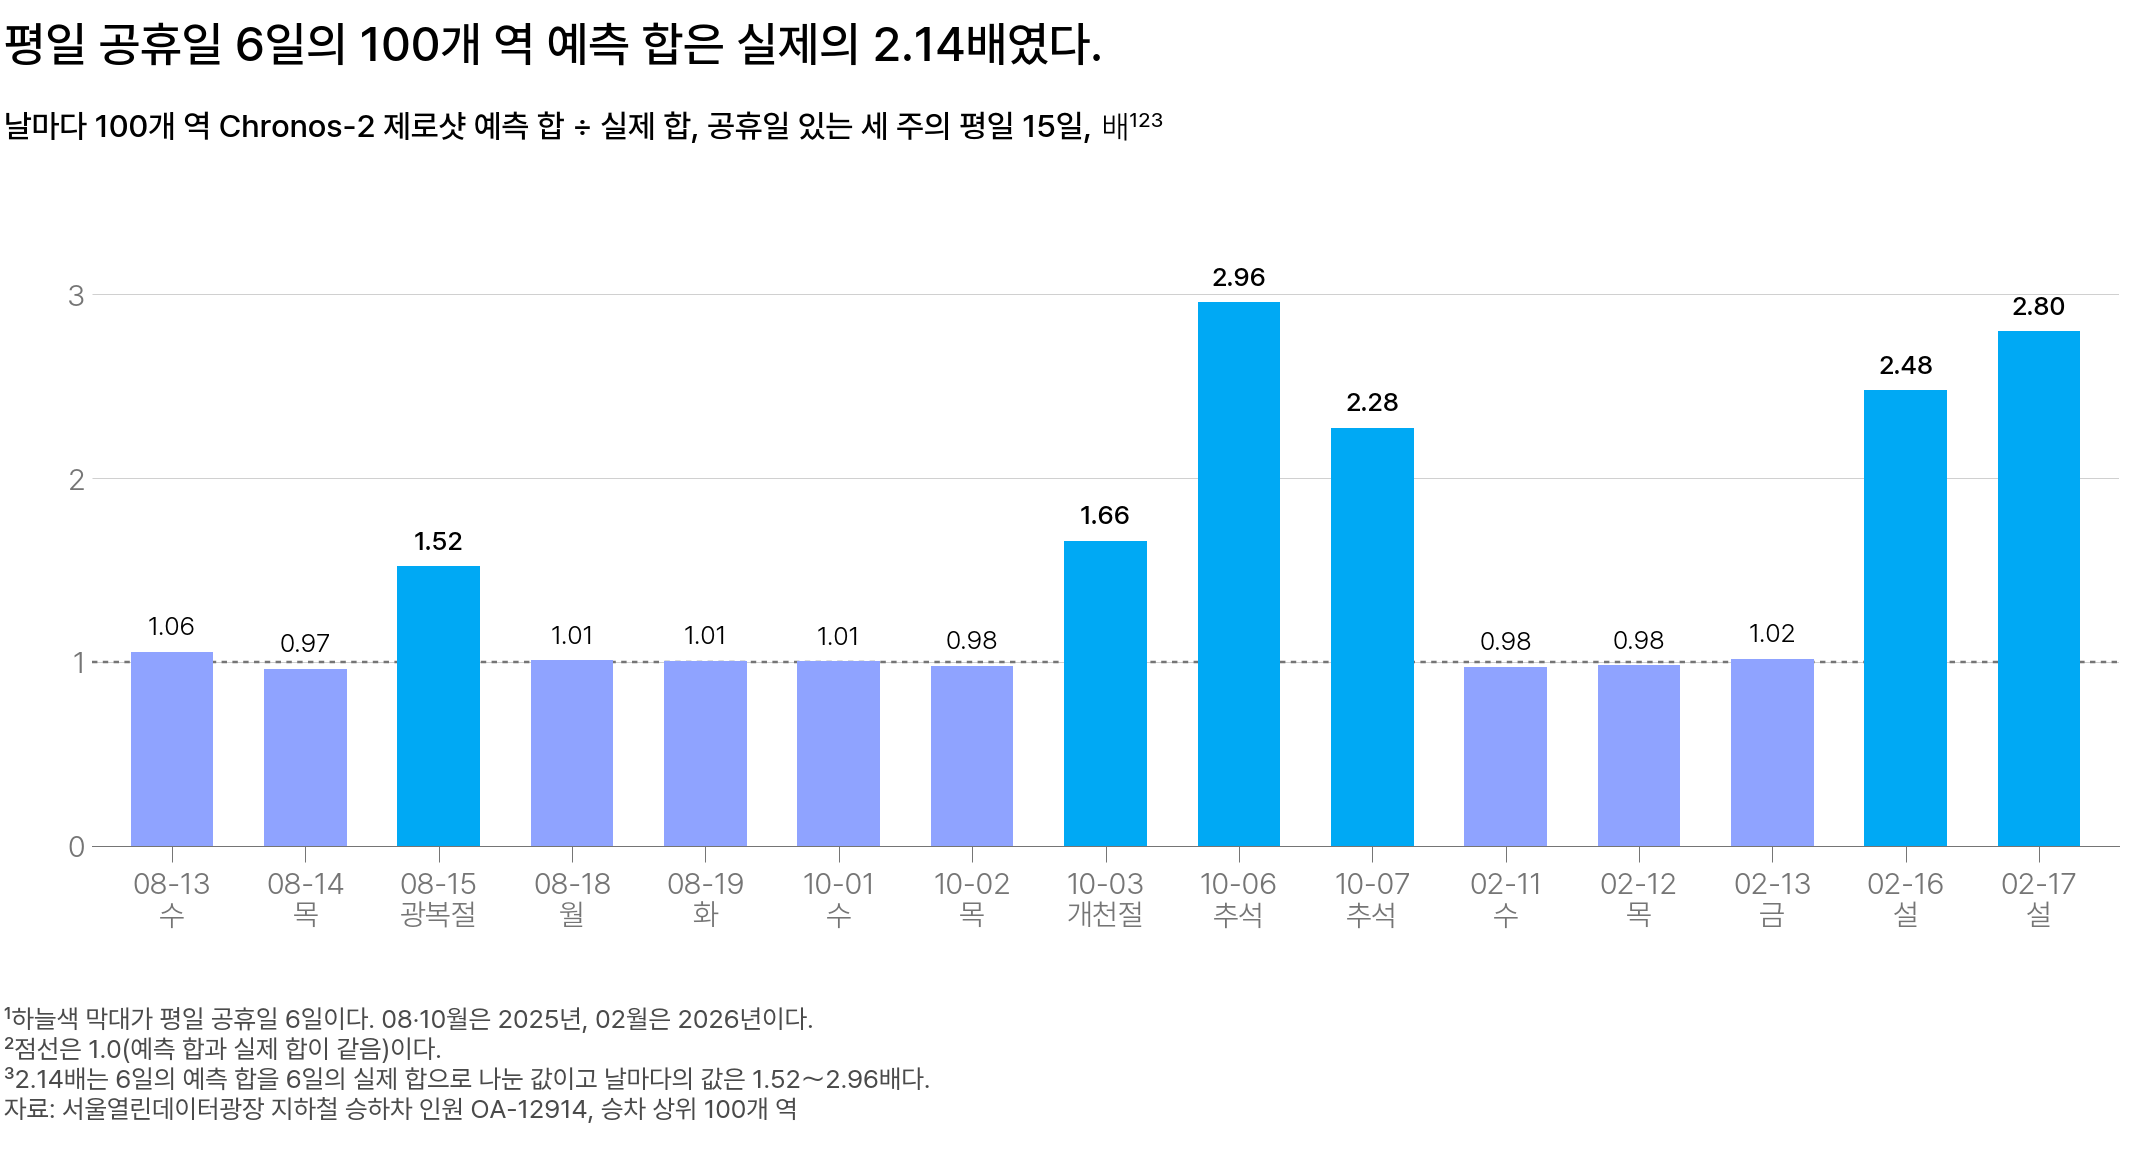

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 공휴일 있는 세 주의 평일 15일, 세로축은 날마다 100개 역 Chronos-2 제로샷 예측 합을 실제 합으로 나눈 값(배)이다. 하늘색 막대가 평일 공휴일 6일, 연한 파란색 막대가 나머지 평일 9일이고, 점선은 1.0 이다</em></p>

막대가 1 이면 예측 합과 실제 합이 같고, 2 면 실제의 두 배입니다.

| 무엇을 보나 | 값 | 어디서 온 수인가 |
|---|---:|---|
| 평일 공휴일 6일의 합 | 2.14배 | 6일의 100개 역 예측 합 ÷ 실제 합 |
| 6일 모두 높게 예측한 역 | 96개 역 | 역마다 6일을 비교해 센 수 |
| 나머지 평일 9일 | 날마다 0.97～1.06배 | 그림의 연한 파란색 막대 |
| 평일 공휴일 날만 채점한 MASE | 4.670～8.323 | 원점 셋마다 공휴일 날만 모아 채점. 1 이면 평소 빗나가던 크기 |

**넘친 것은 평일 공휴일 6일이고, 같은 주의 다른 평일 9일은 실제와 거의 같습니다.**

### 계절 나이브는 달랐나 [필수]

> **[예측] 같은 6일에 1주일 전 값을 그대로 예측값으로 쓰는 계절 나이브는 100개 역 합으로 실제의 몇 배를 예측했을까요?**
>
> 1. 1배 가까이 예측해 Chronos-2 보다 훨씬 덜 넘쳤다
> 2. 2배 남짓 예측해 Chronos-2 와 거의 같았다
> 3. 3배 넘게 예측해 Chronos-2 보다 더 넘쳤다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

둘째 보기가 맞습니다.

계절 나이브도 같은 6일에 실제의 2.14배를 예측했습니다.

| 방식 | 평일 공휴일 6일의 예측 합 ÷ 실제 합 | 어디서 온 수인가 |
|---|---:|---|
| Chronos-2 제로샷 | 2.14배 | 앞 화면 표의 첫 행 |
| 계절 나이브 | 2.14배 | 같은 6일의 1주일 전 승차 합 ÷ 실제 합 |

평일 공휴일의 1주일 전은 여느 평일이라, 계절 나이브는 평일 승차를 예측값으로 씁니다.

평가표의 다섯 방식은 모두 공휴일 날짜를 입력으로 받지 않습니다.

**두 방식 모두 평일 공휴일을 평일 크기로 예측했습니다.**

<details class="lms-extra"><summary>더 깊이 — 계절 나이브도 2.14배로 넘친 까닭</summary>

강남역의 평일 공휴일 세 날로 보면 이렇습니다.

| 강남역의 날 | 실제 승차 | 계절 나이브(1주일 전) | Chronos-2 제로샷 0.5 분위수 |
|---|---:|---:|---:|
| 2025-10-03(금, 개천절) | 43,721명 | 97,311명 | 94,670명 |
| 2026-02-16(월, 설 연휴) | 21,453명 | 91,553명 | 92,202명 |
| 2026-02-17(화, 설 연휴) | 14,973명 | 95,750명 | 94,837명 |

두 방식 모두 세 날을 평일과 같은 승차 인원으로 예측했습니다. 그래서 100개 역 합도 둘 다 2.14배 안팎입니다(제로샷 2.139, 계절 나이브 2.143).

</details>

### 왜 평일 공휴일을 평일처럼 예측하나 [필수]

입력에는 지난 512일의 승차 값만 있고, 예측할 날이 공휴일이라는 표시가 없습니다.

$$
\textbf{지난 512일의 승차 값(공휴일 표시 없음)} \;\longrightarrow\; \textbf{평일 공휴일도 여느 평일 크기로 예측}
$$

아래는 원점 2025-10-01 의 강남역 두 날입니다(출력 표의 `"0.5"` 열).

| 강남역 예측할 날 | 입력 | 0.5 분위수 예측 | 실제 승차 |
|---|---|---:|---:|
| 10-02(목, 평일) | 2024-05-07～2025-09-30 의 512일 | 87,953명 | 89,738명 |
| 10-03(금, 개천절) | 같은 512일 | 94,670명 | 43,721명 |

두 날의 예측은 같은 512일을 입력해 받은 값입니다. 개천절도 여느 금요일 크기로 예측해, 예측이 실제의 두 배를 넘습니다.

지난 공휴일도 낮은 승차 값으로 입력에 있습니다. 지난해 개천절도 이 512일 안에 있습니다.

어텐션은 1년 전 그날의 값도 한 단계에 반영할 수 있습니다. 그러나 그 낮은 값은 512일 가운데 하루뿐이고 공휴일이라는 표시가 없어, 올해 같은 날을 낮게 예측할 근거가 되지 못합니다.

**역·날짜·승차 세 열만 전달한 예측에는 올해 공휴일 날짜가 없어서, 평일 공휴일을 평일처럼 예측합니다.**

<details class="lms-extra"><summary>자세히 — 식으로 쓰면 입력에 무엇이 있나</summary>

제로샷 예측을 식으로 쓰면 이렇습니다. 등호 오른쪽의 괄호 안이 모델이 받는 입력입니다.

$$
\hat y_{o}, \dots, \hat y_{o+6} = g_{\theta}(y_{o-512}, \dots, y_{o-1})
$$

- $o$: 예측 원점
- $\hat y_{o}, \dots, \hat y_{o+6}$: 원점부터 7일의 예측 승차 인원(명)
- $g_{\theta}$: 사전학습으로 정해 고정한 모델 가중치 $\theta$ 로 계산하는 Chronos-2
- $y_{o-512}, \dots, y_{o-1}$: 원점 전날까지 512일의 승차 인원(명)

즉 괄호 안에는 **지난 512일의 승차 값만** 있습니다. 날짜도, 공휴일이라는 표시도 괄호 안에 없습니다.

지난 공휴일은 그 512일 안에 있습니다. 원점 2026-02-11 의 입력 512일을 달력과 대조하면 공휴일이 26일입니다. 그러나 낮은 승차 값으로만 있고, 공휴일이라는 표시는 없습니다.

</details>

<details class="lms-extra"><summary>더 깊이 — 역마다 다른 과대 배수</summary>

평일 공휴일 6일의 예측 합을 역마다 실제 합으로 나눈 값을 **과대 배수**라 부릅니다. 1 이면 예측 합과 실제 합이 같고, 100개 역 전체로는 2.14배였습니다. 역마다 크게 다릅니다.

| 역 | 6일 실제 합 | 6일 예측 합 | 과대 배수 |
|---|---:|---:|---:|
| 2호선 역삼 | 54,526명 | 360,452명 | 6.61배(100개 역 가운데 가장 큼) |
| 2호선 강남 | 166,078명 | 558,236명 | 3.36배 |
| 경부선 용산 | 267,318명 | 278,795명 | 1.04배(100개 역 가운데 가장 작음) |

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Seoul-metro-221-Yeoksam-station-entrance-5-20181121-150456.jpg" alt="2호선 역삼역 5번 출구와 뒤편의 높은 사무용 건물들" width="640" height="360"/>
<p align="center"><em>▲ 2호선 역삼역 5번 출구. 평일 공휴일 6일에 이 역의 제로샷 예측 합은 실제의 6.61배로 100개 역 가운데 가장 컸다 (출처: Wikimedia Commons, Seoul-metro-221-Yeoksam-station-entrance-5-20181121-150456.jpg)</em></p>

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Yongsansta01.jpg" alt="「용산역 Yongsan Station」 글자가 걸린 둥근 유리 외벽의 역 건물" width="480" height="360"/>
<p align="center"><em>▲ 용산역 건물. 경부선 용산은 평일 공휴일 6일의 과대 배수가 1.04 로 100개 역 가운데 가장 작았다 (출처: Wikimedia Commons, Yongsansta01.jpg)</em></p>

제로샷은 평일 공휴일에도 평일 승차 인원을 예측하므로, 과대 배수가 큰 역은 공휴일 승차가 평일보다 크게 줄어드는 역입니다. 역삼은 공휴일 승차가 예측의 6분의 1 에 못 미쳤고, 용산은 공휴일에도 예측과 거의 같았습니다.

과대 배수가 크다고 넘친 인원도 많은 것은 아닙니다. 강남은 3.36배로 역삼보다 작지만, 넘친 인원은 392,158명으로 역삼 305,926명보다 많습니다. 그래서 공휴일 날 인력을 얼마나 줄일지는 배수가 아니라 넘친 명수로 정합니다.

</details>

<div class="lms-summary">

**정리**

Chronos-2 제로샷은 올해 공휴일 날짜를 입력으로 받지 않아, 평일 공휴일을 여느 평일 크기로 예측합니다. 1주일 전 값을 옮기는 계절 나이브도 같은 날에 똑같이 넘칩니다.

**할 일**

- 평일 공휴일이 있는 주에는 공휴일 아닌 평일의 예측만 인력 계획에 씁니다
- 공휴일 날은 인력 계획표에 따로 표시하고, 그날 인력은 이 예측 대신 운영팀이 정합니다
- 공휴일 날짜를 입력으로 받는 예측을 평가표에 더해, 공휴일 있는 세 주에서 계절 나이브보다 낮은지 확인합니다

공휴일 날을 평일과 다르게 예측하려면 공휴일 날짜를 입력으로 받는 예측이 있어야 합니다.

</div>

> **[문제] 지난 공휴일이 입력에 있는데도 평일처럼 예측한 까닭**
>
> 512일 입력에는 지난해 설과 추석도 있습니다. 그런데도 Chronos-2 제로샷은 평일 공휴일을 평일처럼 높게 예측했습니다. 까닭은 무엇이고, 그 주의 어느 날 인력에 이 예측을 쓰고 어느 날에는 쓰지 않을까요?

## 6. 정리와 팀 라운드

평가표 결과로 운영팀에 무엇을 권할까요?

### 사전학습 모델을 평가표에 더하는 차례 [필수]

새 사전학습 모델도 Chronos-2 와 같은 네 가지를 정해 평가표에 더합니다.

| 정할 것 | 이렇게 한다 | 서울 지하철 100개 역에서 |
|---|---|---|
| 전달할 표 | 역·날짜·승차 세 열만 롱 포맷으로 전달한다 | 원점마다 100개 역 × 512일 = 51,200행 |
| 컨텍스트 | 마지막 날을 원점 전날로 두고, 7일을 한 번에 받는다 | 원점 2026-06-24 이면 2025-01-28～2026-06-23 |
| 점 예측 열 | MASE 로 채점하면 `"0.5"` 열을 쓴다 | 원점 5개 모두 `"0.5"` 열이 `predictions` 열과 같았다 |
| 다른 방식과 비교할 때 | 공휴일이 있는 주와 없는 주로 나눠 계절 나이브와 비교한다 | 「4. 서울 지하철 100개 역에 Chronos-2 를 쓰면」의 공휴일 없는 두 주와 공휴일 있는 세 주 |

**네 가지를 같게 정해야 새 모델의 MASE 를 평가표의 다른 방식과 비교할 수 있습니다.**

<details class="lms-extra"><summary>더 깊이 — 날마다 다시 예측한 점수가 좋게 나오는 까닭</summary>

원점에서 7일을 한 번에 받으면, 셋째 날을 예측할 때 원점 뒤 이틀의 실제값은 아직 없습니다. 날마다 그 전날까지의 실제값을 받아 다음 날을 다시 예측하면, 매번 하루 앞만 맞히면 됩니다.

<img src="https://otexts.com/fpp3/toolbox_files/figure-html/cv1-1.png" alt="행마다 학습 관측(파란 점)과 채점 시각(주황 점)이 한 칸씩 늦어지는 시계열 교차 검증 격자" width="640" height="300"/>
<p align="center"><em>▲ 하루 앞 예측. 가로축은 시각이고 한 행이 예측 한 번이다. 행마다 파란 점이 예측에 쓴 관측이고 주황 점이 채점하는 시각이다. 주황 점이 늘 파란 점 바로 다음이라, 채점하는 날의 전날 실제값까지 예측에 쓴다 (출처: Hyndman &amp; Athanasopoulos, Forecasting: Principles and Practice 3rd ed., §5.10)</em></p>

<img src="https://otexts.com/fpp3/toolbox_files/figure-html/cv4-1.png" alt="예측 한 번마다 한 행씩, 파란 점과 주황 점 사이에 회색 점 세 개가 있는 그림" width="640" height="300"/>
<p align="center"><em>▲ 네 시점 앞 예측. 파란 점과 주황 점 사이의 회색 점은 예측하는 시점에 아직 실측이 없는 시각이다. 원점에서 7일을 한 번에 받으면 뒤쪽 날일수록 회색 점이 늘어난다 (출처: Hyndman &amp; Athanasopoulos, Forecasting: Principles and Practice 3rd ed., §5.10)</em></p>

하루 앞 예측은 바로 전날의 실제값까지 입력으로 받아 계산하므로, 여러 날 앞 예측보다 덜 빗나갑니다. 운영하는 수요일 아침에는 그날부터 7일의 인력을 한꺼번에 정합니다. 그래서 평가표에는 원점에서 한 번에 받은 7일을 적습니다. 다른 곳에서 낸 점수를 받으면, 7일을 한 번에 예측한 점수인지 날마다 다시 예측한 점수인지부터 확인합니다.

</details>

<div class="lms-summary">

**정리**

Chronos-2 제로샷은 학습 없이 512일을 입력으로 받습니다. 어텐션은 512일의 패치마다 가중치를 계산해 가중 평균하는 일을 여러 층 되풀이합니다. 공휴일 없는 두 주에는 다섯 방식 가운데 가장 덜 빗나갔고, 공휴일 있는 세 주에는 계절 나이브와 같았습니다. 두 방식 모두 올해 공휴일 날짜를 입력으로 받지 않아, 평일 공휴일을 평일처럼 높게 예측했기 때문입니다.

**할 일**

- 위 표의 차례로 평가표에 Chronos-2 제로샷을 더합니다
- 미세조정은 더하지 않습니다. 원점마다 평균 446초 학습해 줄인 평균 MASE 0.009 가 시드 범위 0.077 보다 작습니다
- 공개일보다 앞선 원점 2개(2025-08-13·2025-10-01)는 사전학습 자료와 겹쳤을 수 있다고 함께 적습니다
- 평일 공휴일이 있는 주에는 공휴일 아닌 평일의 예측만 씁니다

Chronos-2 제로샷은 공휴일 없는 주의 역별 인력 예측 후보로 올립니다.

</div>

## 수업에서 다룰 질문 [필수]

**아래 질문의 답은 수업에서 팀이 함께 정합니다.** 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 공휴일 없는 두 주에서 가장 낮고, 공휴일 있는 세 주에서는 계절 나이브와 같은 모델을 운영에 넣을까**
>
> 운영팀이 다음 주 100개 역의 7일 승차 예측을 직전 7일 평균에서 바꿀지 팀의 의견을 구합니다. 평가표에서 Chronos-2 제로샷은 공휴일 없는 두 주에서 평균 MASE 0.271 로 다섯 방식 가운데 가장 낮았습니다. 같은 두 주에서 계절 나이브는 0.445, 직전 7일 평균은 1.935 였습니다. 학습은 0초이고 원점 하나의 100개 역 예측은 1초 안쪽(Colab T4)이었습니다. 공휴일 있는 세 주에서는 2.763 으로 계절 나이브 2.767 과 거의 같았고, 원점별로 평일 공휴일 날만 모아 채점하면 MASE 가 4.670～8.323 이었습니다. 공개 전 원점 두 곳은 채점 기간이 사전학습 자료에 들어갔는지 확인하지 못했습니다.
> 
> 팀 안에서 의견이 셋으로 나뉘었습니다.
> 
> - **관점 A: 다음 주부터 바꾼다.** 공휴일 없는 두 주의 MASE 가 직전 7일 평균의 7분의 1 보다 작고, 학습 비용도 없다.
> - **관점 B: 아직 바꾸지 않는다.** 인력 배치가 가장 비싸게 틀리는 주는 평일 공휴일이 있는 주인데, 공휴일 있는 세 주에서는 계절 나이브와 다를 것이 없다.
> - **관점 C: 평일 공휴일이 없는 주에만 바꾼다.** 달력은 미리 알 수 있으니 주마다 쓸 모델을 규칙으로 정한다.
> 
> 자기 입장 하나와 근거 세 문장, 그리고 확신도를 정해 오세요.